# 04A · Feature and characteristic atlas

**Advanced movement representation learning — chapter 4, part A.** Status: `AUTHORED — AWAITING USER EXECUTION` (2026-10-12). No cell has been run by the author.

**Question.** Among the Combine measurements that already exist in this project, which have a clear definition, a valid grain and adequate coverage; which are consistent across attempts of the same athlete within position; which keep reproducible information that the official forty and 10-yard split do not explain; and which follow the recording rather than the athlete?

**What this notebook is.** A descriptive measurement-validation study. It consolidates what Phase 03, Phase 04, the sprint reliability rescue and notebooks 00–03 already measured into one table per feature, with the same columns whatever the estimator, and screens it. The only new measurements are four sustained-acceleration features computed on recorded intervals.

**What it is not.** No NFL outcome is read, no NFL model is fitted, and no feature is selected with an NFL value. Nothing is retrained and no upstream artifact is rebuilt or overwritten: outputs go to the `atlas` sub-area.

**Unit of analysis.** The athlete. A forty attempt is never counted as an athlete; intervals resample athletes inside position.

**How to run.** Keep `RUN_MODE = 'smoke'` for a first technical pass (results are not interpretable), then set `RUN_MODE = 'full'`, restart the kernel and run all cells. Notebooks 00–03 must have been run in the same mode.

## Configuration

In [1]:
RUN_MODE = 'full'       # 'smoke' | 'full' — must match the mode notebooks 00, 01, 02 and 03 were run with
FORCE_REBUILD = False    # True = recompute even when the cached atlas tables are current
SAVE_FIGURES = True
SAVE_TABLES = True
SAVE_MODELS = True       # unused here: nothing is trained in notebook 04A
SEED = 20261011          # same seed as notebook 00
DEVICE = 'cpu'           # unused here
NUM_WORKERS = 0          # unused here

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)    # thread and memory limits; call before the first polars import of the kernel

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.research.advanced_movement import atlas as at
from nflbdb.research.advanced_movement import atlas_figures as af
from nflbdb.research.advanced_movement import atlas_validation
from nflbdb.research.advanced_movement import checkpoint as ck
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import data as amd
from nflbdb.research.advanced_movement import fpca_eval as fe
from nflbdb.research.advanced_movement import repr_eval as rv
from nflbdb.research.advanced_movement import sequences as seq
from nflbdb.research.advanced_movement.artifacts import AtlasStore
from nflbdb.research.sprint_rescue import attempts as rescue_attempts
from nflbdb.research.sprint_rescue.config import RescueConfig

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES,
                                save_tables=SAVE_TABLES, save_models=SAVE_MODELS, device=DEVICE, seed=SEED,
                                num_workers=NUM_WORKERS).validate()
acfg = amc.AdvancedConfig().for_mode(controls)
c = at.AtlasConfig().for_mode(controls)
rcfg = RescueConfig()
store = AtlasStore(cfg, controls)     # writes under .../advanced_movement/atlas (smoke: .../_sample/atlas)
up = store.upstream                   # read-only access to the artifacts of notebooks 00-03, same run mode
seed_notes = amc.seed_everything(controls.seed)

NB00, NB01, NB02, NB03 = ('00_research_setup_and_data_audit.ipynb', '01_sequence_eda_and_alignment.ipynb',
                          '02_functional_pca_baseline.ipynb', '03_self_supervised_tcn.ipynb')
manifest = up.require(amd.MANIFEST, NB00)
athletes = up.require(amd.ATHLETES, NB00)
seq_frames = up.require(seq.SEQ_FRAMES, NB01)
windows = up.require(ck.WINDOWS, NB02)
fpca_gate = up.require(fe.GATE, NB02)
fpca_scores = up.require(fe.ATHLETE_SCORES, NB02)
methods = up.require(rv.METHODS, NB03)
method_summary = up.require(rv.SUMMARY, NB03)
trace = up.require(rv.ICC, NB03)
previous = up.read_json('research_metadata', NB00)
if previous.get('seed') != controls.seed:
    seed_00 = previous.get('seed')
    raise ValueError(f'SEED = {controls.seed} but notebook 00 was run with seed {seed_00}: use the same seed')

inputs = amd.AdvInputs(cfg, acfg)
attempts = inputs.rescue_attempts()
if attempts is None:
    raise FileNotFoundError('the sprint rescue attempt table (attempt_censoring_diagnostics) is missing: it is the source of the '
                            'forty attempt features and is not rebuilt here')
mart = inputs.mart()
registry, catalog = at.read_registry(cfg), at.read_catalog(cfg)
ss = seq.SequenceSet.from_frames(seq_frames, manifest)

n_tracked = athletes.filter(pl.col('n_primary_eligible') >= 1).height
n_repeat = athletes.filter(pl.col('has_repeat')).height
label = 'TECHNICAL CHECK ONLY — a few athletes; no number below is a result' if controls.smoke else 'full population'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · {windows.height} eligible forty attempts of {n_tracked} tracked '
                 f'athletes, {n_repeat} with a repeated attempt · seed {controls.seed}'))
display(store.describe())

**Run mode: `full`** (full population) · 793 eligible forty attempts of 418 tracked athletes, 375 with a repeated attempt · seed 20261011

what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_moveme…"
"""datasets (Parquet + schema sid…","""warehouse/gold/advanced_moveme…"
"""figures (PNG 300 DPI, SVG, PDF…","""reports/figures/advanced_movem…"
"""models and fitted preprocessin…","""artifacts/models/advanced_move…"


## 1 · What is reused and what is new

The milestone is a consolidation, so the first table is an inventory: every feature family, the persisted output it is read from, whether that output is present in this run mode, and whether anything had to be added. Two things are new: four sustained-acceleration features on measured intervals (section 4) and the characterisation engine that gives every feature the same table (section 5). Everything else is read.

Findings carried into this notebook (executed earlier, not recomputed): forty speed measurements are highly repeatable and largely redundant with the official forty; most acceleration measurements are less repeatable, and their repeatability differs by position and cohort; a forty recording starts after the first movement and ends near peak speed; the 2025 cohort has about a quarter of the positional noise of 2023 and 2024; no functional PCA component is at once repeatable, non-redundant and independent of the recording window; TCN-B on speed against distance improved repeat-attempt identification in notebook 03, with NFL value untested.

In [3]:
inventory = at.reuse_inventory(store, cfg)
with pl.Config(tbl_rows=40, fmt_str_lengths=110):
    display(inventory)
absent = inventory.filter(~pl.col('present'))
if absent.height:
    display(Markdown('**Missing inputs:** ' + '; '.join(absent['artifact'].to_list())
                     + '. Rows that depend on them are absent from the atlas; nothing is rebuilt here.'))
registry_note = ('not found — other-drill and event rows are absent from the dictionary' if registry is None
                 else f'{registry.height} feature × drill rows read as evidence (nothing recomputed)')
display(Markdown(f'**Phase 04 registry:** {registry_note}. **Phase 04 catalog:** {len(catalog)} definitions.'))

family,artifact,present,status,use
str,str,bool,str,str
"""F1 official Combine""","""gold.mart_athlete_research_base""",true,"""reused""","""official results (12 columns), cast to numbers"""
"""F2 / F4 / F6 forty attempt features""","""sprint_rescue.attempt_censoring_diagnostics""",true,"""reused""","""speed, acceleration, speed-band and sprint-model values per attempt; fit validity flags"""
"""F2 other drills / F3 events""","""phase_04 V_feature_validation_registry""",true,"""reused (evidence only)""","""status and repeatability per feature × drill; nothing recomputed"""
"""F4 sprint model""","""phase_03 sprint fit, as carried by the sprint rescue""",true,"""reused""","""no second fitter is written"""
"""F5 functional PCA""","""fpca_component_gate / fpca_athlete_scores""",true,"""reused""","""component evidence of notebook 02"""
"""F5 encoders""","""repr_method_summary / repr_trace_reliability / *_attempt_embeddings""",true,"""reused""","""TCN-A, TCN-B (8-d) and the 16-d sensitivity of notebook 03"""
"""F6 sustained acceleration""","""accel_sustained, accel_initial, accel_v2_5 / v4_7 / v2_7 (sprint rescue)""",true,"""reused""","""best 0.5 s mean, first second after onset, mean acceleration between two speeds"""
"""F6 sustained acceleration""","""atlas_sustained (this notebook)""",true,"""NEW (4 features)""","""fixed 0.5 s and 1.0 s windows, speed gain over a distance, time between two speeds — all anchored on a recorde…"
"""F7 acquisition""","""sequence_window_flags""",true,"""reused""","""recording window, noise and quality flags of notebook 02"""


**Phase 04 registry:** 1357 feature × drill rows read as evidence (nothing recomputed). **Phase 04 catalog:** 24 definitions.

## 2 · Synthetic validation

Before any real number is read, the helpers are checked on data with a known answer: unique dictionary keys, the athlete / attempt grain, recovery of a known ICC, athlete-level bootstrap, position-adjusted statistics, the sustained-acceleration rules (measured intervals only), the screening rules, the whole engine on a fixture, artifact isolation, and the absence of any NFL identifier in the atlas modules. Every row must read `PASS`; the cell stops otherwise.

In [4]:
validation_report = atlas_validation.run_all(atlas_validation.ATLAS_CHECKS)
with pl.Config(tbl_rows=30, fmt_str_lengths=160):
    display(validation_report)
atlas_validation.assert_all_passed(validation_report)

00:59:18 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:UP] computing (never run)
00:59:18 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:UP] integrity_table: 2 rows → C:/Users/myben/AppData/Local/Temp/tmpbl6vrhih/warehouse/gold/advanced_movement/integrity_table.parquet
00:59:18 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:ATLAS] computing (never run)
00:59:18 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ATLAS] integrity_table: 2 rows → C:/Users/myben/AppData/Local/Temp/tmpbl6vrhih/warehouse/gold/advanced_movement/atlas/integrity_table.parquet
00:59:18 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ATLAS_FREEZE] transfer_exploratory_registry: 0 rows → C:/Users/myben/AppData/Local/Temp/tmpbl6vrhih/warehouse/gold/advanced_movement/atlas/transfer_exploratory_registry.parquet
00:59:18 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ATLAS_FRE

check,status,detail
str,str,str
"""unique_feature_dictionary_keys""","""PASS""","""55 definitions, one row per feature_id; a drill-specific variant keeps its own row; a duplicate is refused"""
"""aggregation_grain""","""PASS""","""108 attempts stay attempts; the athlete table holds 60 athletes; a missing value keeps its reason"""
"""known_icc_recovery""","""PASS""","""ICC 0.801 [0.762, 0.835] for a true 0.80; pooled over positions 0.967"""
"""athlete_level_bootstrap""","""PASS""","""athlete-level SE is 1.40 × the attempt-level one; ICC interval width 0.26 at 60 athletes, 0.15 at 240; the two-way matched interval is reproducible"""
"""position_adjusted_statistics""","""PASS""","""pooled ρ -0.88 becomes +0.02 within position; a copy of the forty is flagged redundant"""
"""sustained_features_use_measured_intervals_only""","""PASS""","""1.0 s mean acceleration 4.025 against 4.025 analytic; absent intervals stay missing with a reason"""
"""screening_rules""","""PASS""","""grades follow the stated rules; a low stopwatch correlation without reliable unexplained variance is not called new"""
"""engine_end_to_end""","""PASS""","""211 characteristic rows over 55 features satisfy their contracts; planted repeatable speed ICC 1.00, planted noise ICC -0.01"""
"""artifact_integrity""","""PASS""","""atlas outputs live in their own area (smoke under _sample); upstream files are byte-identical after a build; the shortlist is written once"""


## 3 · Feature dictionary

The dictionary is assembled from the configurations and registries that define the features, never typed a second time: the sprint rescue feature specification, the Phase 04 registry and catalog, the functional PCA gate and the method table of notebook 03. One row is one definition. The same name on another drill or position stratum is another feature and keeps its own row; a forty feature that this atlas characterises itself is not listed a second time from the registry.

Seven families: **F1** official Combine, **F2** engineered kinematics, **F3** maneuvers and events, **F4** sprint model, **F5** learned representations, **F6** sustained acceleration, **F7** acquisition / nuisance. `design` says which characterisation procedure applies; `role` separates a reference, a candidate, a fit diagnostic and an acquisition variable. A learned representation is one row as a whole vector: a single coordinate of an encoder is not a feature.

In [5]:
REGISTRY_FILE = cfg.paths.tables / 'phase_04' / 'reliability' / 'V_feature_validation_registry.csv'
DICT_PARAMS = {'atlas': c.params(), 'rescue': rcfg.params(), 'catalog_definitions': len(catalog)}
DICT_FILES = [up.parquet(fe.GATE), up.parquet(rv.METHODS), REGISTRY_FILE]
dictionary = store.build('ATLAS_DICTIONARY', [at.DICTIONARY],
                         lambda: {at.DICTIONARY.name: at.build_dictionary(c, rcfg, registry, catalog, fpca_gate, methods)},
                         params=DICT_PARAMS, files=DICT_FILES)[at.DICTIONARY.name]
at.assert_unique_keys(dictionary)

FORTY_ONLY = ~pl.col('feature_id').str.contains(':', literal=True)     # identifiers of other drills contain ':'
display(Markdown(f'**Feature dictionary: {dictionary.height} definitions** (unit: definition; key `feature_id`, verified unique)'))
display(dictionary.group_by('family', 'design', 'role').agg(pl.len().alias('definitions'), pl.col('drill').n_unique().alias('drills'),
                                                            pl.col('measurement_status').first())
        .sort('family', 'design', 'role'))
display(Markdown('**Definitions characterised here or in notebooks 02–03** (forty-yard dash, official measurements, learned representations)'))
with pl.Config(tbl_rows=90, fmt_str_lengths=100):
    display(dictionary.filter(FORTY_ONLY).select('feature_id', 'units', 'grain', 'role', 'measurement_status', 'interpretation_status',
                                                 'time_or_distance_window', 'definition'))

00:59:18 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:ATLAS_DICTIONARY] computing (never run)
00:59:19 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ATLAS_DICTIONARY] feature_dictionary: 1,409 rows → warehouse/gold/advanced_movement/atlas/feature_dictionary.parquet


**Feature dictionary: 1409 definitions** (unit: definition; key `feature_id`, verified unique)

family,design,role,definitions,drills,measurement_status
str,str,str,u32,u32,str
"""F1""","""static_athlete""","""reference""",12,1,"""measured"""
"""F2""","""repeated_attempt""","""candidate""",8,1,"""derived"""
"""F2""","""repeated_attempt""","""descriptive""",861,52,"""reused evidence only"""
"""F3""","""event_rate""","""descriptive""",464,52,"""reused evidence only"""
"""F4""","""model_parameter""","""candidate""",4,1,"""model-based"""
"""F4""","""model_parameter""","""diagnostic""",4,1,"""model-based"""
"""F5""","""functional_score""","""candidate""",24,1,"""learned"""
"""F5""","""neural_embedding""","""candidate""",8,1,"""learned"""
"""F6""","""repeated_attempt""","""candidate""",9,1,"""derived"""


**Definitions characterised here or in notebooks 02–03** (forty-yard dash, official measurements, learned representations)

feature_id,units,grain,role,measurement_status,interpretation_status,time_or_distance_window,definition
str,str,str,str,str,str,str,str
"""F1.official.cmb_arm_length""","""in""","""athlete""","""reference""","""measured""","""interpretable""","""official test""","""arm length measured at the Combine"""
"""F1.official.cmb_bench_reps""","""reps""","""athlete""","""reference""","""measured""","""interpretable""","""official test""","""official bench-press repetitions"""
"""F1.official.cmb_broad_jump""","""in""","""athlete""","""reference""","""measured""","""interpretable""","""official test""","""official standing broad jump"""
"""F1.official.cmb_combine_height""","""in""","""athlete""","""reference""","""measured""","""interpretable""","""official test""","""height measured at the Combine"""
"""F1.official.cmb_combine_weight""","""lb""","""athlete""","""reference""","""measured""","""interpretable""","""official test""","""weight measured at the Combine"""
"""F1.official.cmb_forty""","""s""","""athlete""","""reference""","""measured""","""interpretable""","""official test""","""official Combine forty-yard-dash time"""
"""F1.official.cmb_hand_size""","""in""","""athlete""","""reference""","""measured""","""interpretable""","""official test""","""hand size measured at the Combine"""
"""F1.official.cmb_short_shuttle""","""s""","""athlete""","""reference""","""measured""","""interpretable""","""official test""","""official 20-yard short-shuttle time"""
"""F1.official.cmb_ten_yd_split""","""s""","""athlete""","""reference""","""measured""","""interpretable""","""official test""","""official split of the forty at 10 yards"""


## 4 · Sustained acceleration (F6): what exists, what is added

Already measured, and reused as they are: the best 0.5 s mean acceleration (`accel_sustained`), the mean acceleration in the first second after detected onset (`accel_initial`), and the mean acceleration between two speeds (`accel_v2_5`, `accel_v4_7`, `accel_v2_7`).

Added here, four features only, all on **measured intervals**. Each is anchored on a speed the recording contains — the moment speed first reaches the anchor speed — so it does not depend on where the recording starts in time:

- mean acceleration over the 0.5 s and over the 1.0 s that follow the anchor;
- speed gained over a fixed distance after the anchor;
- time between two speeds, only when both crossings are recorded.

The unobserved start of the sprint is not reconstructed and the end is not extrapolated. When the recording starts above the anchor speed, stops before the window ends, or never reaches the upper speed, the value is missing and the reason is kept.

In [6]:
sustained = store.build('ATLAS_SUSTAINED', [at.SUSTAINED], lambda: {at.SUSTAINED.name: at.sustained_table(ss, c)},
                        params={'atlas': c.params()}, files=[up.parquet(seq.SEQ_FRAMES)])[at.SUSTAINED.name]
NEW = [s[0] for s in at.sustained_specs(c)]
display(Markdown(f'**Anchor speed {c.anchor_speed:g} yd/s, upper speed {c.upper_speed:g} yd/s, distance {c.gain_distance_yd:g} yd** '
                 '(fixed before any value was read)'))
with pl.Config(fmt_str_lengths=140):
    display(dictionary.filter(pl.col('family') == 'F6').select('feature_name', 'units', 'source_module', 'time_or_distance_window', 'definition'))
display(Markdown('**New features: attempts measured and attempts missing, by reason** (unit: forty attempt — a count of recordings, not of athletes)'))
display(sustained.group_by('feature', 'missing_reason').agg(pl.len().alias('attempts'), pl.col('nfl_id').n_unique().alias('athletes'),
                                                            pl.col('value').median().alias('median_value'))
        .with_columns(pl.when(pl.col('missing_reason') == '').then(pl.lit('measured')).otherwise(pl.col('missing_reason')).alias('missing_reason'))
        .sort('feature', 'attempts', descending=[False, True]))

00:59:19 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:ATLAS_SUSTAINED] computing (never run)


00:59:19 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ATLAS_SUSTAINED] atlas_sustained: 3,172 rows → warehouse/gold/advanced_movement/atlas/atlas_sustained.parquet


**Anchor speed 4 yd/s, upper speed 8 yd/s, distance 10 yd** (fixed before any value was read)

feature_name,units,source_module,time_or_distance_window,definition
str,str,str,str,str
"""accel_0p5s_from_v4""","""yd/s²""","""nflbdb.research.advanced_movement.atlas""","""0.5 s after the anchor speed""","""mean acceleration over the 0.5 s that follow the moment speed first reaches 4 yd/s (speed gain / window, both ends inside the recording)"""
"""accel_1s_from_v4""","""yd/s²""","""nflbdb.research.advanced_movement.atlas""","""1 s after the anchor speed""","""mean acceleration over the 1 s that follow the moment speed first reaches 4 yd/s (speed gain / window, both ends inside the recording)"""
"""accel_initial""","""yd/s²""","""nflbdb.research.sprint_rescue""","""whole recording""","""average acceleration in the first second after detected onset"""
"""accel_sustained""","""yd/s²""","""nflbdb.research.sprint_rescue""","""whole recording""","""best 0.5 s average acceleration"""
"""accel_v2_5""","""yd/s²""","""nflbdb.research.sprint_rescue""","""speed band""","""mean acceleration while speed rises from 2 to 5 yd/s"""
"""accel_v2_7""","""yd/s²""","""nflbdb.research.sprint_rescue""","""speed band""","""mean acceleration while speed rises from 2 to 7 yd/s"""
"""accel_v4_7""","""yd/s²""","""nflbdb.research.sprint_rescue""","""speed band""","""mean acceleration while speed rises from 4 to 7 yd/s"""
"""speed_gain_10yd_from_v4""","""yd/s""","""nflbdb.research.advanced_movement.atlas""","""10 yd after the anchor speed""","""speed gained over the 10 yd of path that follow the moment speed first reaches 4 yd/s"""
"""time_v4_to_v8_s""","""s""","""nflbdb.research.advanced_movement.atlas""","""4 → 8 yd/s""","""time between the first crossings of 4 and 8 yd/s (defined only when both crossings are recorded)"""


**New features: attempts measured and attempts missing, by reason** (unit: forty attempt — a count of recordings, not of athletes)

feature,missing_reason,attempts,athletes,median_value
str,str,u32,u32,f64
"""accel_0p5s_from_v4""","""measured""",793,418,4.800029
"""accel_1s_from_v4""","""measured""",793,418,4.014759
"""speed_gain_10yd_from_v4""","""measured""",793,418,4.861416
"""time_v4_to_v8_s""","""measured""",793,418,0.994116


## 5 · Characterisation engine

Each feature goes through the procedure its measurement design allows. The output table has the same columns for all; `reliability_method` and `source` say what was used.

| Design | Reliability | Stopwatch | Acquisition |
|---|---|---|---|
| static athlete measurement (F1) | not estimable: one official value per athlete | Spearman and R² with forty and 10-yard, within position | not applicable |
| repeated attempt (F2, F6, F7) | stratified ICC(1) within position, athlete bootstrap; SEM; attempt 2 − attempt 1; rank agreement; by cohort; under quality filters | same, on the mean of the athlete's attempts; cohort-adjusted R²; body size | R² of the attempt-to-attempt change on the change of the recording window; cohort share |
| model parameter (F4) | same, on attempts whose fit passed its flags | same | same |
| functional score (F5) | ICC with the outer fold in the stratum — reused from notebook 02 | reused | reused |
| neural embedding (F5) | rotation-invariant trace reliability and repeat-attempt AUC — reused from notebook 03 | held-out share of the forty the vector explains (reverse direction) | trace R² of the attempt change; cohort probe |
| event count or rate (F3) and other drills | Phase 04 registry evidence only | not characterised here | not characterised here |

A high curve-fit R² of the sprint model is a goodness of fit, not evidence that its parameters are identifiable: the fit R² is kept as a diagnostic row and the parameters are judged by their own repeatability.

In [7]:
d = at.attempt_data(windows, attempts, sustained, dictionary)
a = at.athlete_data(athletes, at.official_table(mart, athletes), dictionary)

CHAR_PARAMS = {'atlas': c.params(), 'seed': controls.seed, 'dictionary_rows': dictionary.height}
CHAR_FILES = [up.parquet(ck.WINDOWS), up.parquet(amd.ATHLETES), up.parquet(seq.SEQ_FRAMES), up.parquet(fe.GATE), up.parquet(rv.SUMMARY),
              up.parquet(rv.ICC), inputs.rescue.parquet(rescue_attempts.ATTEMPTS), REGISTRY_FILE]
tables = store.build('ATLAS_CHARACTERISE', list(at.CHAR_CONTRACTS),
                     lambda: at.characterise_all(dictionary, d, a, c, controls.seed, fpca_gate, method_summary, trace, registry),
                     params=CHAR_PARAMS, files=CHAR_FILES)
chars, coverage, reliability, nuisance = (tables[x.name] for x in (at.CHARACTERISTICS, at.COVERAGE, at.RELIABILITY, at.NUISANCE))
status = store.build('ATLAS_SCREEN', [at.STATUS], lambda: {at.STATUS.name: at.screening_table(chars, dictionary, c)},
                     params=CHAR_PARAMS, files=CHAR_FILES)[at.STATUS.name]
retention = store.build('ATLAS_RETENTION', [at.RETENTION], lambda: {at.RETENTION.name: at.quality_retention(windows)},
                        params={'atlas': c.params()}, files=[up.parquet(ck.WINDOWS)])[at.RETENTION.name]

ALL = chars.filter(pl.col('scope') == 'all').join(status.select('feature_id', 'role', 'grade', 'stopwatch_relation', 'acquisition',
                                                                 'transfer_eligibility'), on='feature_id')
CANDIDATES = ALL.filter(FORTY_ONLY & (pl.col('role') == 'candidate'))
display(Markdown(f'**{chars.height} characteristic rows** for {status.height} features (all athletes, and inside each position). '
                 f'Tracked athletes: {a.ids.size}; eligible attempts: {d.seq_ids.size}.'))
display(Markdown('**Summary by family and design** (unit: feature; forty and official measurements; medians over the features of the row)'))
display(ALL.filter(FORTY_ONLY).group_by('family', 'design', 'role').agg(
    pl.len().alias('features'), pl.col('n_athletes_repeat').max().alias('athletes_repeat_max'),
    pl.col('coverage_athletes').median().alias('coverage_median'), pl.col('reliability').median().alias('reliability_median'),
    pl.col('redundancy_abs').median().alias('abs_rho_stopwatch_median'), pl.col('window_r2').median().alias('window_r2_median'))
        .sort('family', 'design', 'role'))

00:59:19 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:ATLAS_CHARACTERISE] computing (never run)


00:59:34 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ATLAS_CHARACTERISE] atlas_coverage: 468 rows → warehouse/gold/advanced_movement/atlas/atlas_coverage.parquet
00:59:34 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ATLAS_CHARACTERISE] atlas_characteristics: 1,669 rows → warehouse/gold/advanced_movement/atlas/atlas_characteristics.parquet
00:59:34 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ATLAS_CHARACTERISE] atlas_reliability: 472 rows → warehouse/gold/advanced_movement/atlas/atlas_reliability.parquet
00:59:34 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ATLAS_CHARACTERISE] atlas_nuisance_diagnostics: 623 rows → warehouse/gold/advanced_movement/atlas/atlas_nuisance_diagnostics.parquet
00:59:34 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ATLAS_CHARACTERISE] atlas_attempt_features: 31,720 rows → warehouse/gold/advanced_movement/atlas/atlas_attempt_features.parquet


**1669 characteristic rows** for 1409 features (all athletes, and inside each position). Tracked athletes: 418; eligible attempts: 793.

**Summary by family and design** (unit: feature; forty and official measurements; medians over the features of the row)

family,design,role,features,athletes_repeat_max,coverage_median,reliability_median,abs_rho_stopwatch_median,window_r2_median
str,str,str,u32,i64,f64,f64,f64,f64
"""F1""","""static_athlete""","""reference""",12,null,1.0,null,0.436495,null
"""F2""","""repeated_attempt""","""candidate""",8,375,1.0,0.349933,0.312229,0.130789
"""F4""","""model_parameter""","""candidate""",4,345,0.988038,0.435498,0.377009,0.398592
"""F4""","""model_parameter""","""diagnostic""",4,375,1.0,0.109401,0.126908,0.460035
"""F5""","""functional_score""","""candidate""",24,375,null,0.386623,0.19877,0.139914
"""F5""","""neural_embedding""","""candidate""",8,375,null,0.779032,null,0.318782
"""F6""","""repeated_attempt""","""candidate""",9,375,1.0,0.504769,0.476176,0.12711
"""F7""","""repeated_attempt""","""nuisance""",15,375,1.0,0.315981,0.091479,0.267286


## 6 · Coverage and missingness (RQ1)

Denominator everywhere: tracked athletes, that is athletes with at least one eligible forty sequence. Coverage is the share of them with at least one value of the feature. Missing values are kept, with their reason.

**Coverage of official measurements and candidate features** (unit: tracked athlete; attempts counted separately)

feature_id,n_athletes,n_athletes_value,coverage_athletes,n_athletes_repeat,n_attempts,n_attempts_value,missing_reasons
str,i64,i64,f64,i64,i64,i64,str
"""F1.official.cmb_three_cone""",418,161,0.385167,null,null,null,"""not_recorded_officially: 257"""
"""F1.official.cmb_bench_reps""",418,162,0.38756,null,null,null,"""not_recorded_officially: 256"""
"""F1.official.cmb_short_shuttle""",418,177,0.423445,null,null,null,"""not_recorded_officially: 241"""
"""F1.official.cmb_broad_jump""",418,373,0.892344,null,null,null,"""not_recorded_officially: 45"""
"""F1.official.cmb_vertical""",418,386,0.923445,null,null,null,"""not_recorded_officially: 32"""
"""F4.forty.model_a0""",418,413,0.988038,345,793,758,"""sprint_fit_not_ok: 35"""
"""F4.forty.model_a_at_ref""",418,413,0.988038,345,793,758,"""sprint_fit_not_ok: 35"""
"""F4.forty.model_tau_s""",418,413,0.988038,345,793,758,"""sprint_fit_not_ok: 35"""
"""F4.forty.model_vmax""",418,413,0.988038,345,793,758,"""sprint_fit_not_ok: 35"""


**Distribution and plausibility** (unit: attempt for attempt features, athlete for official measurements; implausible = outside the broad screen of the dictionary, counted and never removed)

feature_id,mean,sd,p05,p50,p95,implausible_share,sd_within_position,cv_within_position_pct
str,f64,f64,f64,f64,f64,f64,f64,f64
"""F1.official.cmb_arm_length""",32.357955,1.400064,30.0,32.375,34.5,0.0,1.104486,3.413338
"""F1.official.cmb_bench_reps""",21.716049,5.751013,13.0,22.0,31.0,0.0,3.851702,17.736661
"""F1.official.cmb_broad_jump""",118.418231,9.07418,102.6,120.0,132.0,0.0,5.886328,4.970796
"""F1.official.cmb_combine_height""",74.506878,2.632218,70.0,74.9375,78.375,0.0,1.679848,2.254621
"""F1.official.cmb_combine_weight""",246.327751,52.838655,181.0,241.5,326.0,0.0,17.404916,7.065755
"""F1.official.cmb_forty""",4.736866,0.310208,4.37,4.625,5.273,0.0,0.151457,3.197415
"""F1.official.cmb_hand_size""",9.555024,0.608352,8.625,9.5,10.5,0.0,0.52321,5.475754
"""F1.official.cmb_short_shuttle""",4.469774,0.254636,4.074,4.45,4.902,0.0,0.159951,3.578511
"""F1.official.cmb_ten_yd_split""",1.633062,0.115577,1.5,1.59,1.84,0.0,0.051676,3.164337


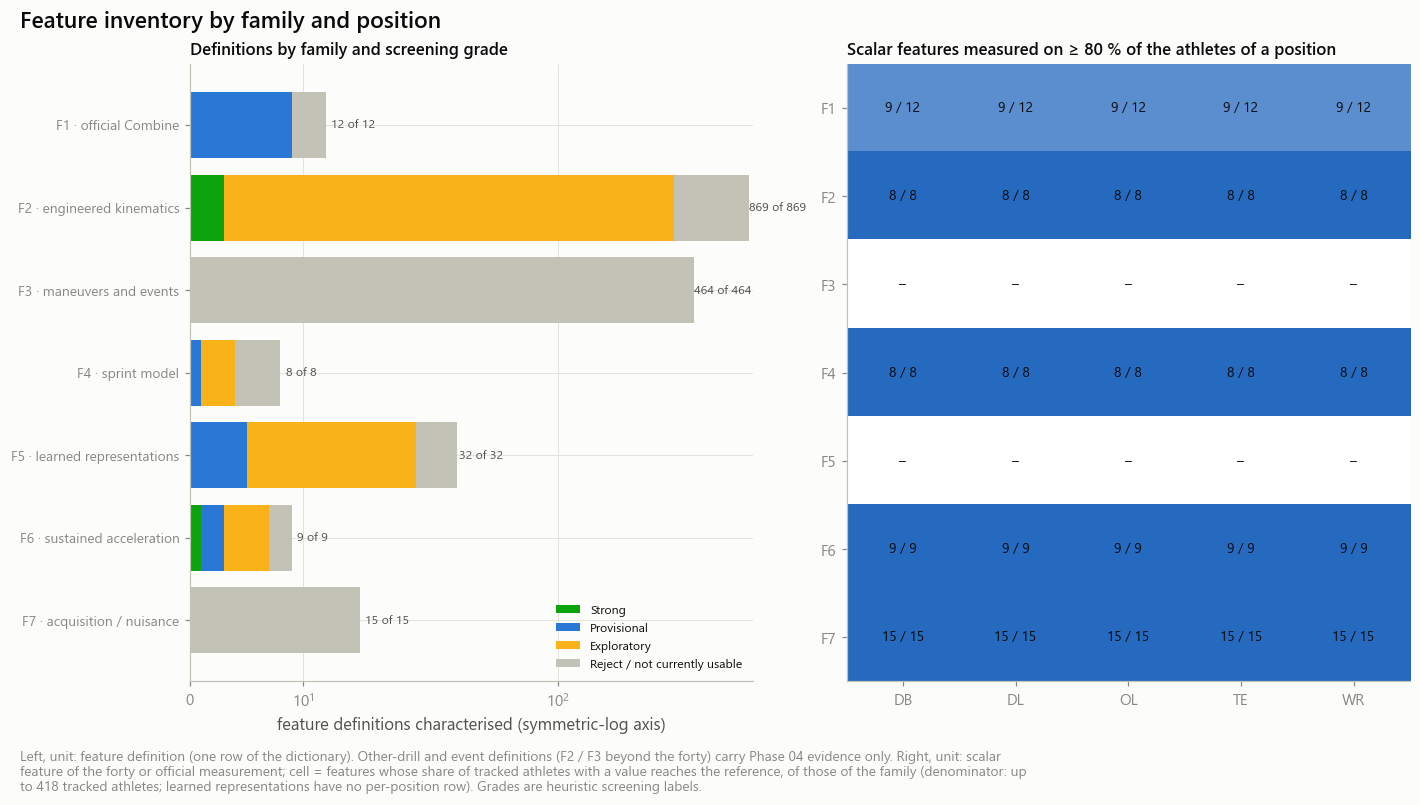

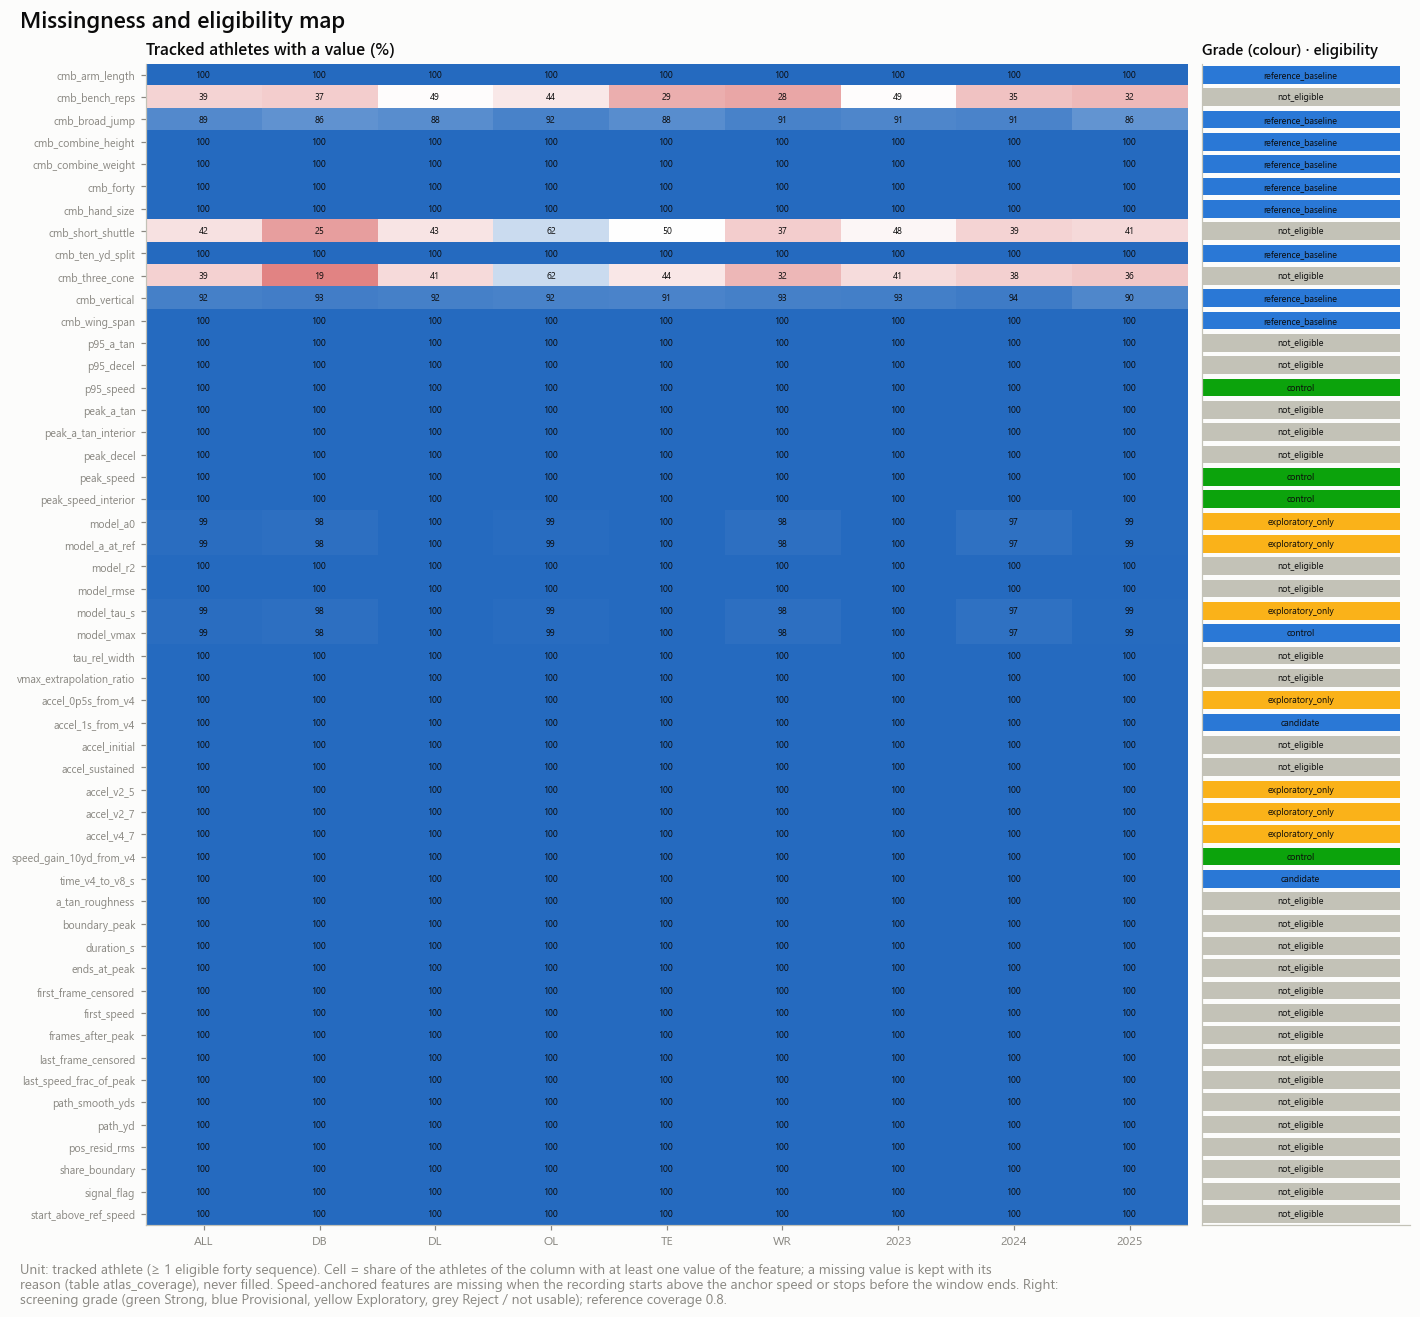

In [8]:
cov_all = coverage.filter(FORTY_ONLY & (pl.col('group_type') == 'all')).join(status.select('feature_id', 'family', 'role'), on='feature_id')
display(Markdown('**Coverage of official measurements and candidate features** (unit: tracked athlete; attempts counted separately)'))
with pl.Config(tbl_rows=70, fmt_str_lengths=120):
    display(cov_all.filter(pl.col('role').is_in(['reference', 'candidate']))
            .select('feature_id', 'n_athletes', 'n_athletes_value', 'coverage_athletes', 'n_athletes_repeat', 'n_attempts',
                    'n_attempts_value', 'missing_reasons').sort('coverage_athletes', 'feature_id'))
display(Markdown('**Distribution and plausibility** (unit: attempt for attempt features, athlete for official measurements; '
                 'implausible = outside the broad screen of the dictionary, counted and never removed)'))
with pl.Config(tbl_rows=70):
    display(CANDIDATES.vstack(ALL.filter(pl.col('role') == 'reference'))
            .select('feature_id', 'mean', 'sd', 'p05', 'p50', 'p95', 'implausible_share', 'sd_within_position', 'cv_within_position_pct')
            .sort('feature_id'))

n_all = str(a.ids.size) + ' tracked athletes'
store.show(af.plot_inventory(dictionary, status, coverage, c), 'AM04A_01_feature_inventory', {'status': status.select('feature_id', 'family', 'grade')},
           publication=True, source='feature_dictionary, atlas_feature_status, atlas_coverage', n=f'{dictionary.height} definitions; {n_all}')
store.show(af.plot_missingness(coverage, status, c), 'AM04A_02_missingness_eligibility_map', {'coverage': coverage.filter(FORTY_ONLY)},
           publication=False, source='atlas_coverage, atlas_feature_status', n=n_all)

## 7 · Reliability (RQ2)

Within-position ICC(1) with a 95 % athlete bootstrap, the standard error of measurement in the unit of the feature, the difference between the first two attempts, and their rank agreement. Then the same ICC inside each position, inside each draft cohort, and under the nested quality filters. A quality filter that raises an ICC by removing athletes is reported, not adopted.

**Repeat-attempt reliability of the candidate features** (unit: athlete with a repeat; within position)

feature_id,n_athletes_repeat,reliability,reliability_lower,reliability_upper,sem,reliability_of_mean,repeat_diff_mean,repeat_diff_sd,repeat_spearman,reliability_cohort_min,reliability_cohort_max,reliability_s2,reliability_s3,repeat_retained_s3
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""F5.fpca.A_alt_origin_at_ref_sp…",372,0.959134,0.946545,0.965517,null,0.977953,null,null,null,0.930705,null,null,0.968097,null
"""F5.fpca.A_speed_by_distance.pc…",375,0.953262,0.937165,0.962957,null,0.974807,null,null,null,0.923522,null,null,0.962968,null
"""F2.forty.p95_speed""",375,0.948451,0.935946,0.958416,0.089088,0.972149,-0.018074,0.124853,0.929002,0.933705,0.957845,0.948738,0.950622,0.677333
"""F2.forty.peak_speed_interior""",375,0.945949,0.932811,0.955902,0.090637,0.970762,-0.016201,0.127322,0.927187,0.928922,0.956321,0.946559,0.948211,0.677333
"""F2.forty.peak_speed""",375,0.942363,0.928543,0.95259,0.095346,0.968768,-0.021024,0.133369,0.920948,0.923925,0.952633,0.9429,0.944952,0.677333
"""F4.forty.model_vmax""",345,0.874121,0.839754,0.89984,0.169502,0.927246,-0.023526,0.238901,0.834685,0.765136,0.932096,0.896609,0.898595,0.695652
"""F5.fpca.C_alt_origin_at_ref_sp…",372,0.831071,0.697344,0.915469,null,0.902893,null,null,null,0.619457,null,null,0.939619,null
"""F6.forty.time_v4_to_v8_s""",375,0.82411,0.779076,0.864288,0.076057,0.898875,-0.006252,0.107523,0.728783,0.767958,0.880035,0.845325,0.845982,0.677333
"""F6.forty.speed_gain_10yd_from_…",375,0.814403,0.753171,0.859137,0.120335,0.892757,-0.002331,0.170391,0.812245,0.707637,0.878703,0.868785,0.873726,0.677333


**Whole-vector representations** (rotation-invariant trace reliability and repeat-attempt AUC, reused from notebook 03)

feature_id,n_athletes_repeat,reliability,reliability_lower,reliability_upper,retrieval_auc,retrieval_auc_lower,retrieval_auc_upper,note
str,i64,f64,f64,f64,f64,f64,f64,str
"""F5.vector.FPCA_A_K2""",375,0.851733,0.79305,0.890496,0.776179,0.744975,0.806438,null
"""F5.vector.FPCA_B_K5""",375,0.478528,0.339785,0.566137,0.68268,0.648413,0.715275,null
"""F5.vector.FPCA_C_K2""",375,0.403023,0.207489,0.603012,0.733702,0.702748,0.766353,null
"""F5.vector.TCNA_A""",375,0.738614,0.622535,0.824933,0.831626,0.805972,0.857686,"""flagged collapsed in notebook …"
"""F5.vector.TCNA_A_E16""",375,0.723827,0.594582,0.833134,0.854727,0.831589,0.878579,"""flagged collapsed in notebook …"
…,…,…,…,…,…,…,…,…
"""F5.vector.TCNA_C""",375,0.426338,0.222879,0.620416,0.771938,0.740614,0.801803,"""flagged collapsed in notebook …"
"""F5.vector.TCNB_A""",375,0.925027,0.898236,0.937213,0.873452,0.856494,0.890426,null
"""F5.vector.TCNB_A_E16""",375,0.928466,0.91055,0.935404,0.88011,0.86419,0.896704,"""flagged collapsed in notebook …"


**Reliability inside each position** (unit: athlete of the position; small groups have wide intervals)

feature_id,position:DB,position:DL,position:OL,position:TE,position:WR
str,f64,f64,f64,f64,f64
"""F2.forty.p95_a_tan""",0.385036,0.635007,0.408617,0.302822,0.055094
"""F2.forty.p95_decel""",0.324094,0.3413,0.150022,0.371999,0.217702
"""F2.forty.p95_speed""",0.915081,0.976395,0.93326,0.925571,0.892382
"""F2.forty.peak_a_tan""",0.399455,0.570299,0.489064,0.241477,0.060781
"""F2.forty.peak_a_tan_interior""",0.399455,0.570299,0.489064,0.241477,0.060781
"""F2.forty.peak_decel""",0.413843,0.030461,0.093892,-0.040126,0.292616
"""F2.forty.peak_speed""",0.903472,0.973702,0.925155,0.912663,0.888476
"""F2.forty.peak_speed_interior""",0.910496,0.974961,0.926552,0.923766,0.892361
"""F4.forty.model_a0""",0.343672,0.716217,0.686854,0.301379,0.040671


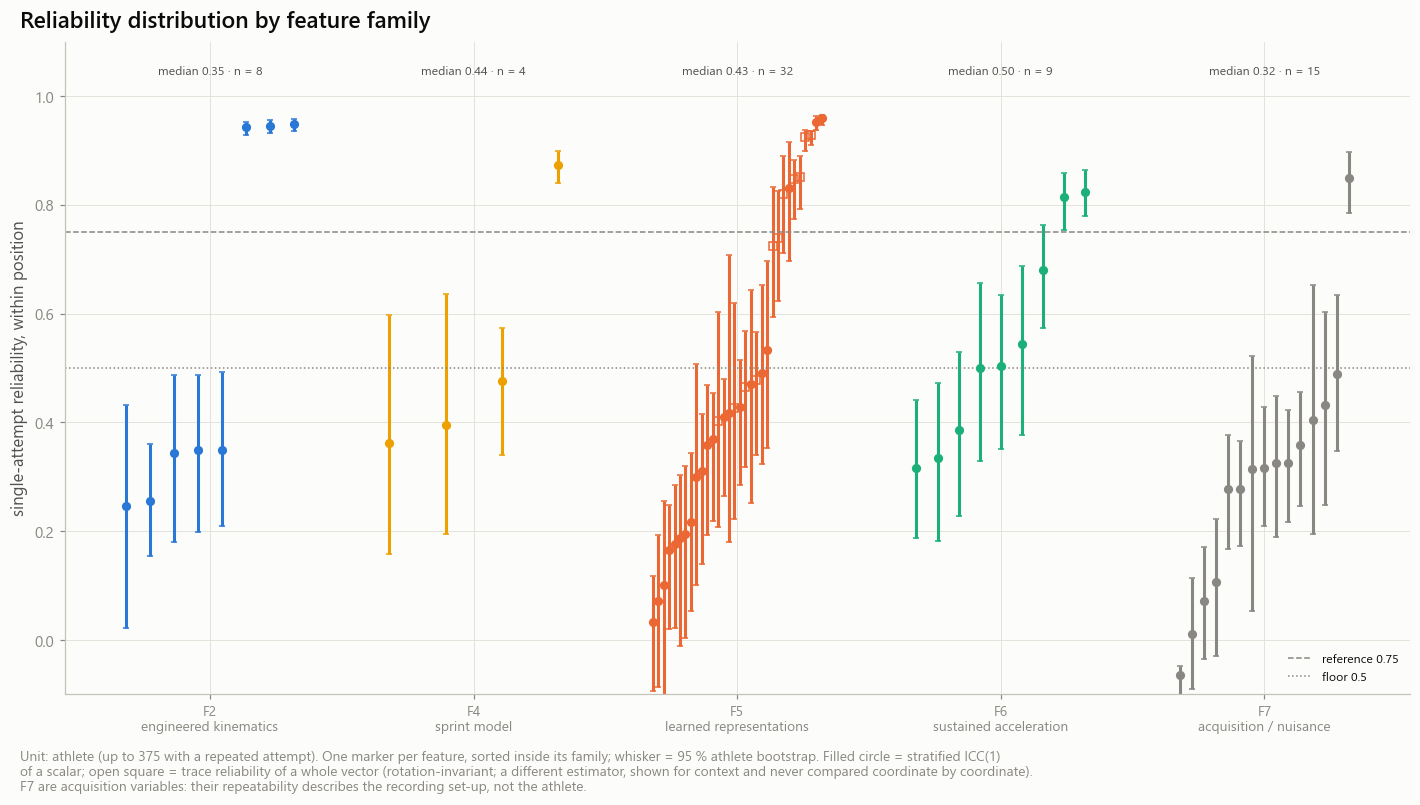

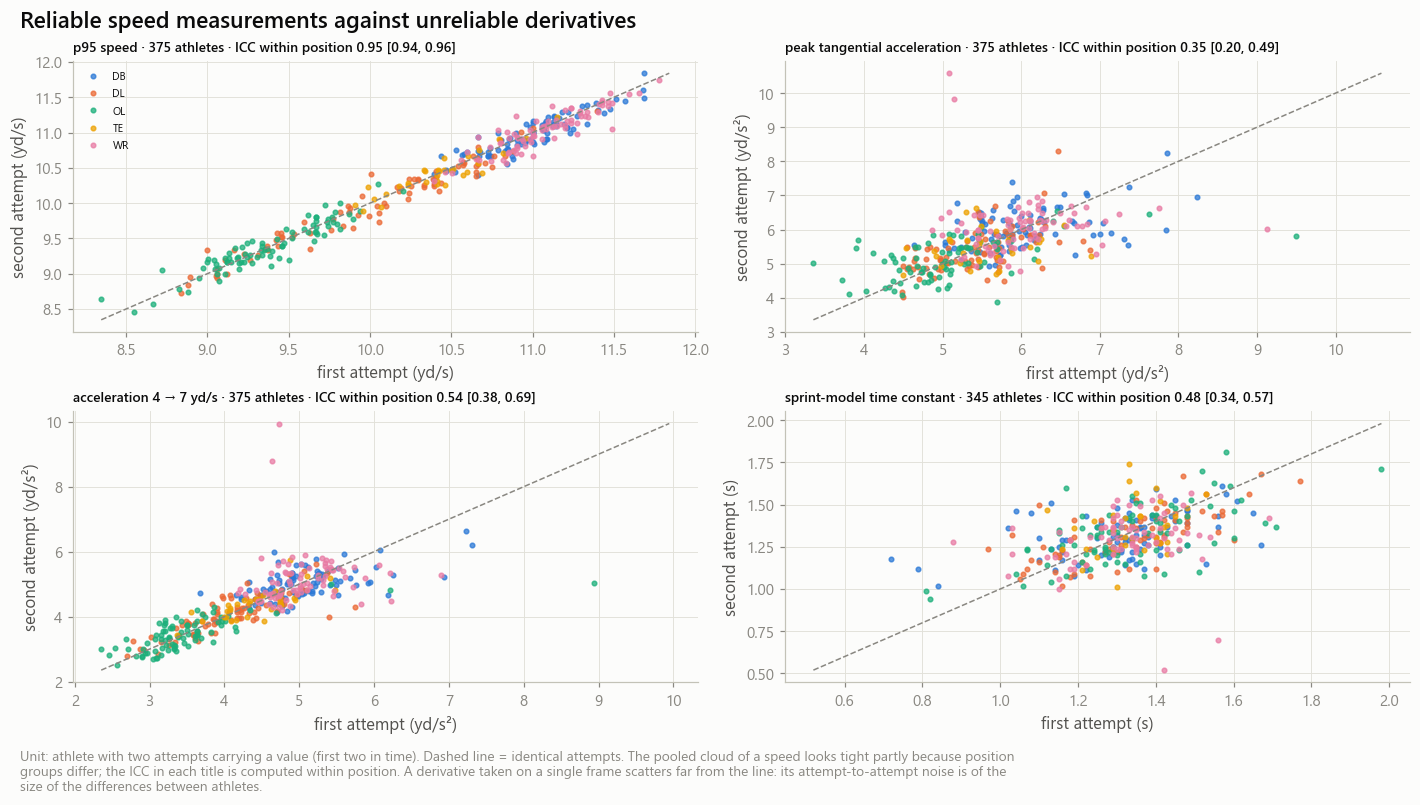

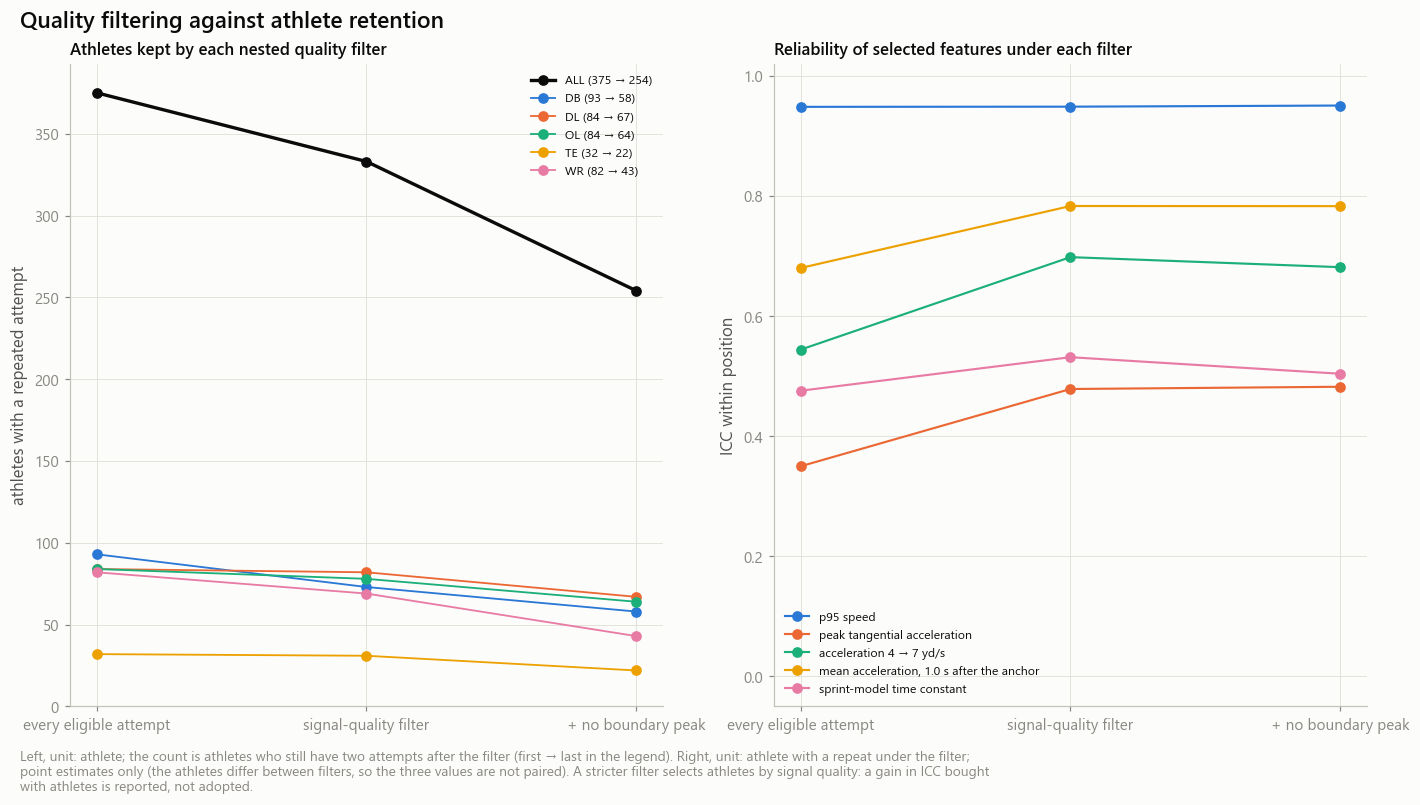

In [9]:
display(Markdown('**Repeat-attempt reliability of the candidate features** (unit: athlete with a repeat; within position)'))
with pl.Config(tbl_rows=70):
    display(CANDIDATES.filter(pl.col('retrieval_auc').is_null())
            .select('feature_id', 'n_athletes_repeat', 'reliability', 'reliability_lower', 'reliability_upper', 'sem', 'reliability_of_mean',
                    'repeat_diff_mean', 'repeat_diff_sd', 'repeat_spearman', 'reliability_cohort_min', 'reliability_cohort_max',
                    'reliability_s2', 'reliability_s3', 'repeat_retained_s3').sort('reliability', descending=True, nulls_last=True))
display(Markdown('**Whole-vector representations** (rotation-invariant trace reliability and repeat-attempt AUC, reused from notebook 03)'))
display(ALL.filter(pl.col('retrieval_auc').is_not_null())
        .select('feature_id', 'n_athletes_repeat', 'reliability', 'reliability_lower', 'reliability_upper', 'retrieval_auc',
                'retrieval_auc_lower', 'retrieval_auc_upper', 'note').sort('feature_id'))
display(Markdown('**Reliability inside each position** (unit: athlete of the position; small groups have wide intervals)'))
by_position = (chars.filter(FORTY_ONLY & pl.col('scope').str.starts_with('position:') & pl.col('reliability').is_not_null())
               .join(status.filter(pl.col('role') == 'candidate').select('feature_id'), on='feature_id'))
with pl.Config(tbl_rows=70):
    display(by_position.pivot(on='scope', index='feature_id', values='reliability').sort('feature_id'))

FILTER_FEATURES = [('F2.forty.p95_speed', 'p95 speed'), ('F2.forty.peak_a_tan', 'peak tangential acceleration'),
                   ('F6.forty.accel_v4_7', 'acceleration 4 → 7 yd/s'), ('F6.forty.' + NEW[1], 'mean acceleration, 1.0 s after the anchor'),
                   ('F4.forty.model_tau_s', 'sprint-model time constant')]
EXAMPLES = [('F2.forty.p95_speed', 'p95 speed', 'yd/s'), ('F2.forty.peak_a_tan', 'peak tangential acceleration', 'yd/s²'),
            ('F6.forty.accel_v4_7', 'acceleration 4 → 7 yd/s', 'yd/s²'), ('F4.forty.model_tau_s', 'sprint-model time constant', 's')]
n_rep = str(int(CANDIDATES['n_athletes_repeat'].max() or 0)) + ' athletes with a repeat (at most)'
store.show(af.plot_reliability_by_family(chars, status, c), 'AM04A_04_reliability_by_family',
           {'reliability': ALL.filter(FORTY_ONLY).select('feature_id', 'family', 'reliability', 'reliability_lower', 'reliability_upper')},
           publication=True, source='atlas_characteristics', n=n_rep)
store.show(af.plot_repeat_examples(tables[at.ATTEMPT_VALUES.name], windows, reliability, EXAMPLES), 'AM04A_08_reliable_speed_vs_derivatives',
           publication=True, source='atlas_attempt_features, atlas_reliability', n=n_rep)
store.show(af.plot_quality_retention(retention, reliability, FILTER_FEATURES), 'AM04A_05_quality_filter_vs_retention',
           {'retention': retention}, publication=False, source='atlas_quality_retention, atlas_reliability', n=n_all)

## 8 · Stopwatch redundancy (RQ3)

For each feature, at athlete level and within position: the Spearman correlation with the official forty and with the 10-yard split, the share of its variance the two explain together (with a bootstrap interval), the same within position × cohort, and the share explained by weight and height.

A low correlation with the forty is **not** treated as novelty. A noisy feature is weakly correlated with everything. The quantity that matters is the reliable variance the official times do not explain: `reliable_unique_share = max(reliability of the athlete mean − stopwatch R², 0)`, a lower bound. The label `beyond_stopwatch` requires that reliability to exceed the upper bound of the stopwatch R² by a margin; `low_correlation_only` is the label of a feature that is merely uncorrelated.

**Association with the official times** (unit: athlete; within position; intervals 95 %)

feature_id,rho_forty,rho_forty_lower,rho_forty_upper,rho_ten,redundancy_abs,r2_stopwatch,r2_stopwatch_lower,r2_stopwatch_upper,r2_stopwatch_cohort_adj,r2_body,reliability_of_mean,reliable_unique_share,stopwatch_relation
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""F5.fpca.A_alt_origin_at_ref_sp…",0.128161,0.03218,0.221799,0.027305,0.128161,0.029583,0.005695,0.067711,null,0.002345,0.62782,0.598237,"""low_correlation_only"""
"""F4.forty.model_tau_s""",-0.082044,-0.177597,0.015042,0.017984,0.082044,0.029151,0.005839,0.07223,0.038957,0.003399,0.624835,0.595683,"""low_correlation_only"""
"""F5.fpca.B_alt_boundary_kept.pc…",0.19877,0.104393,0.2896,0.101573,0.19877,0.030479,0.009751,0.065109,null,0.014606,0.587555,0.557076,"""low_correlation_only"""
"""F5.fpca.B_accel_by_speed.pc2""",0.202749,0.108491,0.293393,0.102388,0.202749,0.02966,0.008883,0.068014,null,0.011838,0.567973,0.538314,"""low_correlation_only"""
"""F5.fpca.A_speed_by_distance.pc…",0.127711,0.031723,0.221364,0.036362,0.127711,0.020097,0.00352,0.056296,null,0.003824,0.514034,0.493937,"""low_correlation_only"""
"""F5.fpca.C_speed_by_time.pc2""",0.269157,0.17738,0.356292,0.157078,0.269157,0.049486,0.024049,0.083607,null,0.024548,0.527243,0.477756,"""low_correlation_only"""
"""F6.forty.accel_initial""",-0.172544,-0.264523,-0.077454,-0.174229,0.174229,0.042772,0.019694,0.078795,0.055309,0.012119,0.466758,0.423986,"""low_correlation_only"""
"""F6.forty.accel_v2_5""",-0.280074,-0.366557,-0.188792,-0.253014,0.280074,0.123185,0.081908,0.181455,0.1335,0.027603,0.543281,0.420097,"""low_correlation_only"""
"""F5.fpca.B_accel_by_speed.pc3""",-0.183528,-0.275041,-0.088719,-0.076357,0.183528,0.042679,0.015891,0.086878,null,0.003651,0.460436,0.417757,"""low_correlation_only"""


**Official measurements against the forty and the 10-yard split** (unit: athlete; a reference is never correlated with itself)

feature_id,n_athletes_value,coverage_athletes,rho_forty,rho_ten,r2_stopwatch,r2_body,cohort_r2
str,i64,f64,f64,f64,f64,f64,f64
"""F1.official.cmb_arm_length""",418,1.0,0.07331,0.111284,0.011621,0.338871,0.028116
"""F1.official.cmb_bench_reps""",162,0.38756,0.112014,-0.020884,0.04406,0.049201,0.002482
"""F1.official.cmb_broad_jump""",373,0.892344,-0.556269,-0.526037,0.456376,0.25496,0.002786
"""F1.official.cmb_combine_height""",418,1.0,0.152583,0.121903,0.009851,0.123845,0.002365
"""F1.official.cmb_combine_weight""",418,1.0,0.448963,0.37627,0.393671,0.123845,0.001658
…,…,…,…,…,…,…,…
"""F1.official.cmb_short_shuttle""",177,0.423445,0.478236,0.424188,0.29684,0.178495,0.039759
"""F1.official.cmb_ten_yd_split""",418,1.0,0.662906,null,0.669536,0.35964,0.004199
"""F1.official.cmb_three_cone""",161,0.385167,0.503136,0.452083,0.298744,0.224638,0.001357


**Whole-vector representations**: held-out share of the official forty the vector explains beyond position, and the repeat-attempt AUC left after the cross-fitted removal of official results (notebook 03; audited in notebook 04B)

feature_id,forty_from_feature_r2,retrieval_auc,residual_auc,residual_auc_lower,residual_auc_upper
str,f64,f64,f64,f64,f64
"""F5.vector.FPCA_A_K2""",0.909382,0.776179,0.695215,0.664147,0.726657
"""F5.vector.FPCA_B_K5""",0.420595,0.68268,0.702018,0.668987,0.73437
"""F5.vector.FPCA_C_K2""",0.510011,0.733702,0.67522,0.643677,0.704842
"""F5.vector.TCNA_A""",0.90307,0.831626,0.793806,0.765542,0.821618
"""F5.vector.TCNA_A_E16""",0.909988,0.854727,0.825519,0.799216,0.852476
…,…,…,…,…,…
"""F5.vector.TCNA_C""",0.721646,0.771938,0.715289,0.683342,0.745697
"""F5.vector.TCNB_A""",0.889904,0.873452,0.916759,0.900917,0.932442
"""F5.vector.TCNB_A_E16""",0.899847,0.88011,0.935111,0.920535,0.948459


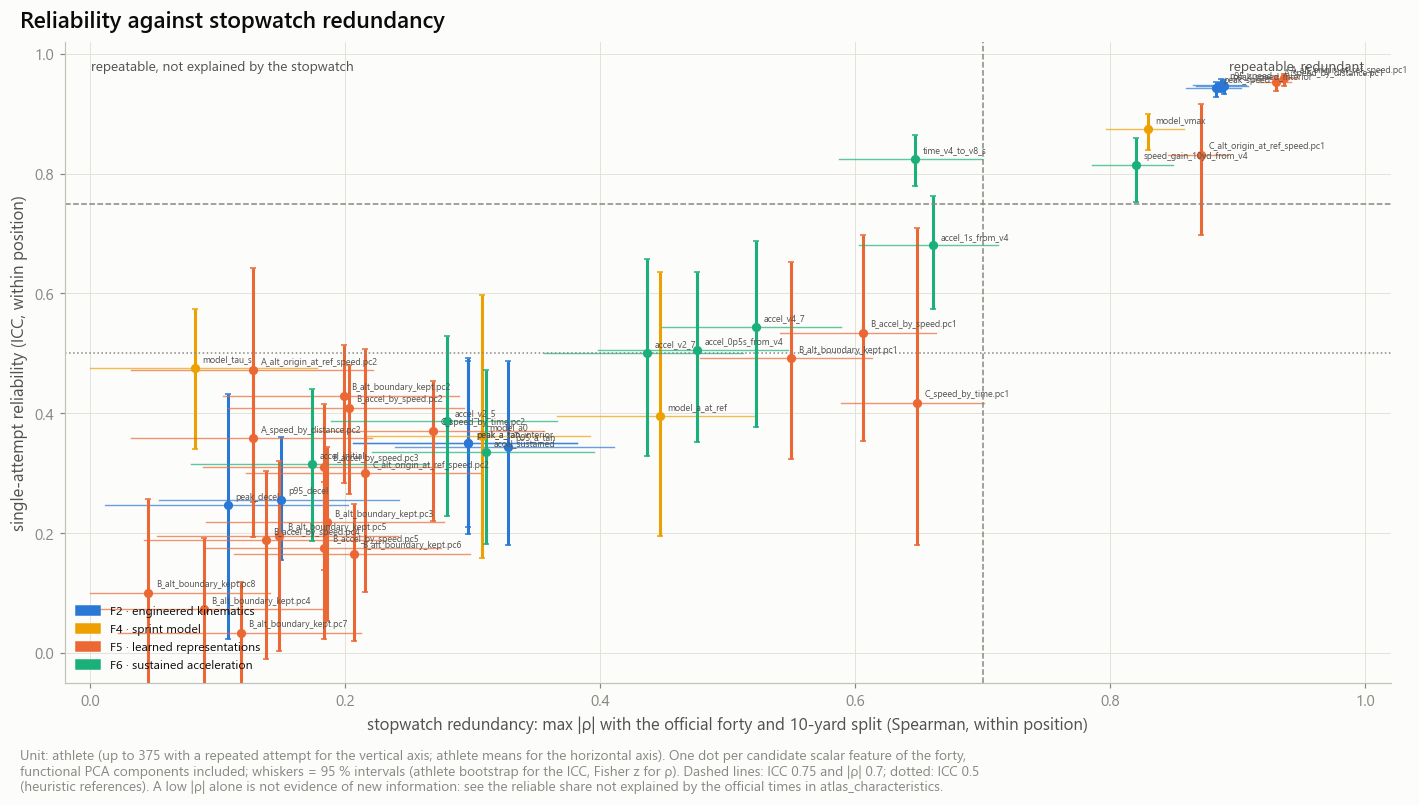

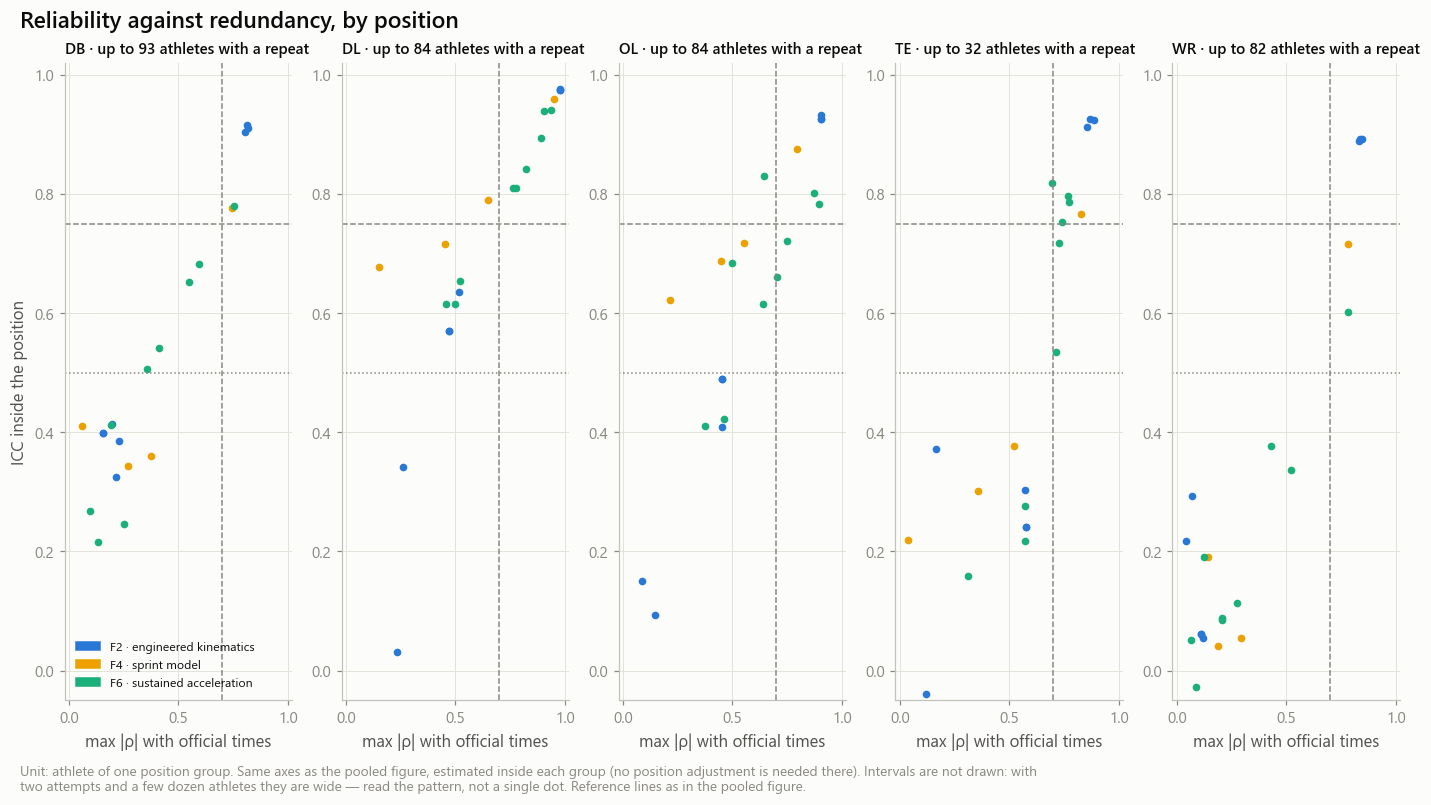

In [10]:
display(Markdown('**Association with the official times** (unit: athlete; within position; intervals 95 %)'))
with pl.Config(tbl_rows=70):
    display(CANDIDATES.filter(pl.col('retrieval_auc').is_null())
            .select('feature_id', 'rho_forty', 'rho_forty_lower', 'rho_forty_upper', 'rho_ten', 'redundancy_abs', 'r2_stopwatch',
                    'r2_stopwatch_lower', 'r2_stopwatch_upper', 'r2_stopwatch_cohort_adj', 'r2_body', 'reliability_of_mean',
                    'reliable_unique_share', 'stopwatch_relation').sort('reliable_unique_share', descending=True, nulls_last=True))
display(Markdown('**Official measurements against the forty and the 10-yard split** (unit: athlete; a reference is never correlated with itself)'))
display(ALL.filter(pl.col('role') == 'reference').select('feature_id', 'n_athletes_value', 'coverage_athletes', 'rho_forty', 'rho_ten',
                                                         'r2_stopwatch', 'r2_body', 'cohort_r2').sort('feature_id'))
display(Markdown('**Whole-vector representations**: held-out share of the official forty the vector explains beyond position, and the '
                 'repeat-attempt AUC left after the cross-fitted removal of official results (notebook 03; audited in notebook 04B)'))
display(ALL.filter(pl.col('retrieval_auc').is_not_null()).select('feature_id', 'forty_from_feature_r2', 'retrieval_auc', 'residual_auc',
                                                                 'residual_auc_lower', 'residual_auc_upper').sort('feature_id'))

store.show(af.plot_reliability_vs_redundancy(chars, status, c), 'AM04A_03_reliability_vs_stopwatch_redundancy',
           {'candidates': CANDIDATES.select('feature_id', 'family', 'reliability', 'reliability_lower', 'reliability_upper', 'redundancy_abs',
                                            'redundancy_lower', 'redundancy_upper', 'reliable_unique_share')},
           publication=True, source='atlas_characteristics', n=n_rep)
store.show(af.plot_reliability_by_position(chars, status, c), 'AM04A_03b_reliability_vs_redundancy_by_position', publication=False,
           source='atlas_characteristics (position scopes)', n=n_rep)

## 9 · Acquisition artifacts (RQ4)

An athlete does not change between two attempts; his recording does. So the sharpest test of an acquisition artifact is within athlete: the change of the feature between attempt 1 and attempt 2 regressed on the change of first-frame speed, recorded duration and frames after the speed peak. The cohort share (within position) shows dependence on the sensor generation. Noise and boundary variables are tested one by one in `atlas_nuisance_diagnostics`.

**Recording-window and cohort dependence of the candidates** (unit: athlete with two attempts for the window, athlete for the cohort)

feature_id,window_r2,window_r2_lower,window_r2_upper,cohort_r2,cohort_probe_gain,reliability_cohort_min,reliability_cohort_max,acquisition
str,f64,f64,f64,f64,f64,f64,f64,str
"""F5.fpca.C_speed_by_time.pc1""",0.95051,0.885031,0.976554,0.028217,null,0.286425,null,"""sensitive"""
"""F5.vector.TCNA_C""",0.794689,0.728764,0.895514,null,0.236842,null,null,"""sensitive"""
"""F5.vector.FPCA_C_K2""",0.773298,0.739499,0.891291,null,0.126794,null,null,"""sensitive"""
"""F5.vector.FPCA_A_K2""",0.670966,0.609497,0.810042,null,0.100478,null,null,"""sensitive"""
"""F5.vector.TCNA_A_E16""",0.625036,0.476483,0.801859,null,0.248804,null,null,"""sensitive"""
"""F6.forty.accel_initial""",0.599544,0.5383,0.793735,0.110566,null,0.221862,0.305538,"""sensitive"""
"""F5.vector.TCNA_A""",0.594742,0.500441,0.773644,null,0.244019,null,null,"""sensitive"""
"""F5.fpca.A_speed_by_distance.pc…",0.593982,0.550632,0.747583,0.086973,null,0.259852,null,"""sensitive"""
"""F4.forty.model_tau_s""",0.488985,0.407277,0.577809,0.123736,null,0.342326,0.56146,"""sensitive"""


**Twenty strongest within-athlete associations with a single acquisition variable** (unit: athlete with two attempts; attempt 2 − attempt 1 on both sides; many pairs were examined, so read the size, not a p-value)

feature_id,variable,n_athletes,spearman,spearman_lower,spearman_upper
str,str,i64,f64,f64,f64
"""F6.forty.accel_initial""","""duration_s""",375,-0.662897,-0.716095,-0.602043
"""F6.forty.accel_initial""","""share_boundary""",375,0.656467,0.594734,0.710503
"""F4.forty.model_a_at_ref""","""duration_s""",345,-0.616696,-0.678127,-0.546708
"""F4.forty.model_a0""","""duration_s""",345,-0.609702,-0.672026,-0.5388
"""F4.forty.model_a_at_ref""","""share_boundary""",345,0.609632,0.538722,0.671966
…,…,…,…,…,…
"""F6.forty.accel_v2_7""","""share_boundary""",372,0.559838,0.485813,0.625889
"""F2.forty.peak_a_tan""","""duration_s""",375,-0.502728,-0.574738,-0.422992
"""F2.forty.peak_a_tan_interior""","""duration_s""",375,-0.502728,-0.574738,-0.422992


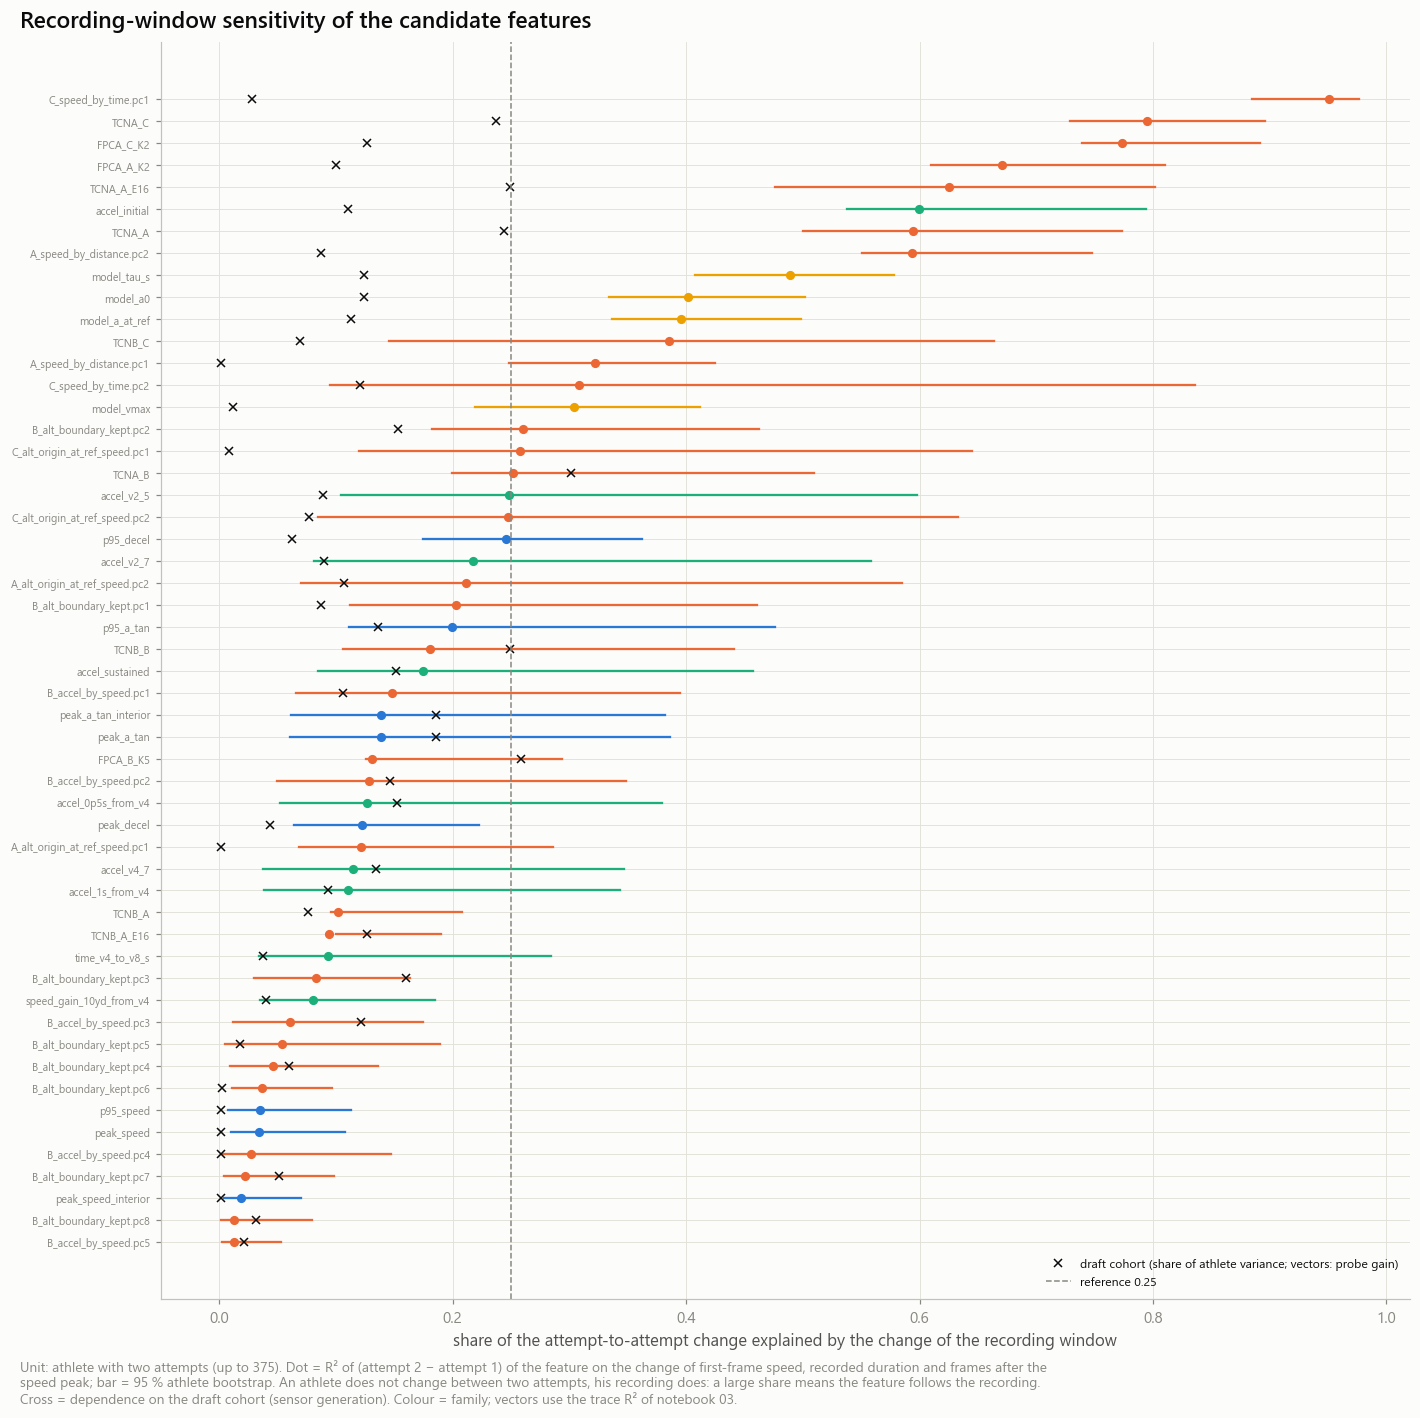

In [11]:
display(Markdown('**Recording-window and cohort dependence of the candidates** (unit: athlete with two attempts for the window, athlete for the cohort)'))
with pl.Config(tbl_rows=70):
    display(CANDIDATES.select('feature_id', 'window_r2', 'window_r2_lower', 'window_r2_upper', 'cohort_r2', 'cohort_probe_gain',
                              'reliability_cohort_min', 'reliability_cohort_max', 'acquisition')
            .sort('window_r2', descending=True, nulls_last=True))
strongest = (nuisance.filter(FORTY_ONLY & (pl.col('level') == 'within_athlete') & pl.col('spearman').is_not_null())
             .join(status.filter(pl.col('role') == 'candidate').select('feature_id'), on='feature_id')
             .with_columns(pl.col('spearman').abs().alias('abs_spearman')).sort('abs_spearman', descending=True).head(20))
display(Markdown('**Twenty strongest within-athlete associations with a single acquisition variable** (unit: athlete with two attempts; '
                 'attempt 2 − attempt 1 on both sides; many pairs were examined, so read the size, not a p-value)'))
display(strongest.select('feature_id', 'variable', 'n_athletes', 'spearman', 'spearman_lower', 'spearman_upper'))

store.show(af.plot_window_sensitivity(chars, status, c), 'AM04A_06_recording_window_sensitivity',
           {'candidates': CANDIDATES.select('feature_id', 'family', 'window_r2', 'window_r2_lower', 'window_r2_upper', 'cohort_r2')},
           publication=True, source='atlas_characteristics', n=n_rep)

## 10 · Redundancy between features

Many features carry the same ordering of athletes. The matrix below is the within-position Spearman correlation between athlete-level features with adequate support (official value, or mean of the attempts), with the functional PCA scores of the primary input beside them. Features are grouped by average linkage while their mean absolute correlation reaches the reference; the most reliable member of a group is its natural representative. Three acquisition variables are included on purpose.

00:59:58 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:ATLAS_REDUNDANCY] computing (never run)
00:59:58 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ATLAS_REDUNDANCY] atlas_redundancy_matrix: 1,225 rows → warehouse/gold/advanced_movement/atlas/atlas_redundancy_matrix.parquet
00:59:58 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:ATLAS_REDUNDANCY] atlas_feature_clusters: 35 rows → warehouse/gold/advanced_movement/atlas/atlas_feature_clusters.parquet


**35 features, 15 groups, 5 of them with more than one feature** (unit: tracked athlete; joined while the mean |ρ| is at least 0.7)

cluster,cluster_size,feature_id,representative,mean_abs_rho_in_cluster
i64,i64,str,str,f64
1,12,"""F2.forty.p95_a_tan""","""F6.forty.time_v4_to_v8_s""",0.845348
1,12,"""F6.forty.accel_sustained""","""F6.forty.time_v4_to_v8_s""",0.845348
1,12,"""F2.forty.peak_a_tan""","""F6.forty.time_v4_to_v8_s""",0.845348
1,12,"""F2.forty.peak_a_tan_interior""","""F6.forty.time_v4_to_v8_s""",0.845348
1,12,"""F6.forty.accel_v2_5""","""F6.forty.time_v4_to_v8_s""",0.845348
1,12,"""F4.forty.model_a0""","""F6.forty.time_v4_to_v8_s""",0.845348
1,12,"""F4.forty.model_a_at_ref""","""F6.forty.time_v4_to_v8_s""",0.845348
1,12,"""F6.forty.accel_0p5s_from_v4""","""F6.forty.time_v4_to_v8_s""",0.845348
1,12,"""F6.forty.accel_v4_7""","""F6.forty.time_v4_to_v8_s""",0.845348


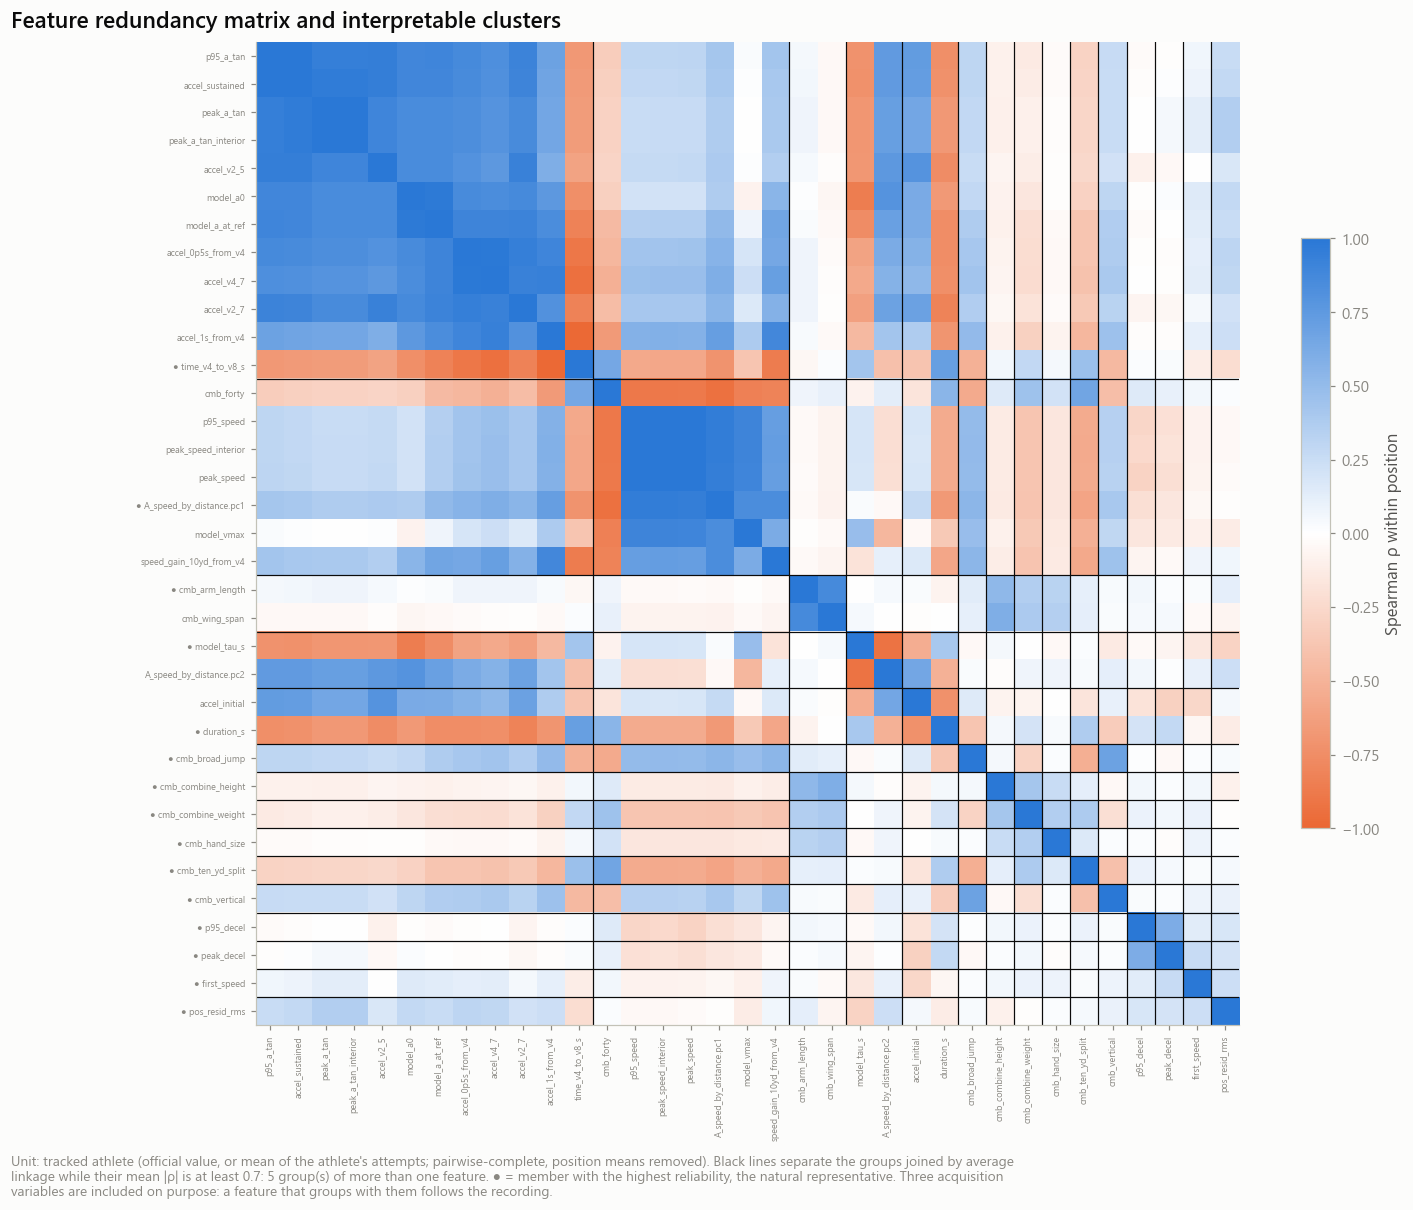

In [12]:
PRIMARY = 'A_speed_by_distance'
gate_a = fpca_gate.filter(pl.col('representation') == PRIMARY)
extra = {}
if gate_a.height:
    k_a = int(gate_a['k'][0])
    sc = fpca_scores.filter((pl.col('representation') == PRIMARY) & (pl.col('k') == k_a) & (pl.col('repeat') == 0))
    for comp in sorted(sc['component'].unique().to_list()):
        one = sc.filter(pl.col('component') == comp)
        extra[f'F5.fpca.{PRIMARY}.pc{comp}'] = (one['nfl_id'].to_numpy(), one['score_mean'].to_numpy())
feats = at.matrix_features(dictionary, status) + list(extra)


def build_redundancy():
    M = at.athlete_matrix(feats, d, a, extra)
    R, N = at.redundancy_matrix(M, a.position)
    return at.redundancy_tables(feats, R, N, status, c)


red = store.build('ATLAS_REDUNDANCY', [at.MATRIX, at.CLUSTERS], build_redundancy, params={**CHAR_PARAMS, 'features': feats},
                  files=[*CHAR_FILES, up.parquet(fe.ATHLETE_SCORES)])
matrix, clusters = red[at.MATRIX.name], red[at.CLUSTERS.name]
groups = clusters.filter(pl.col('cluster_size') > 1)
display(Markdown(f'**{len(feats)} features, {clusters["cluster"].n_unique()} groups, {groups["cluster"].n_unique()} of them with more than one '
                 f'feature** (unit: tracked athlete; joined while the mean |ρ| is at least {c.cluster_rho:g})'))
with pl.Config(tbl_rows=80):
    display(groups.sort('cluster', 'display_order').select('cluster', 'cluster_size', 'feature_id', 'representative', 'mean_abs_rho_in_cluster'))
store.show(af.plot_redundancy_matrix(matrix, clusters, c), 'AM04A_07_feature_redundancy_matrix', {'matrix': matrix, 'clusters': clusters},
           publication=True, source='atlas_redundancy_matrix, atlas_feature_clusters', n=n_all)

## 11 · Screening

Rules, applied to the intervals above (reference lines are heuristics, not scientific boundaries; the continuous evidence is exported beside every label):

- **Reject / not currently usable** — an acquisition variable or a fit diagnostic; rejected or unvalidated upstream; inadequate support; or a reliability interval below the floor.
- **Strong** — reliability interval above the reference and no measured acquisition dependence. A learned vector is capped at Provisional until notebook 04B.
- **Provisional** — at least moderate reliability and no demonstrated acquisition sensitivity. Official measurements are Provisional by construction: they are the reference, and their repeatability cannot be estimated in this dataset.
- **Exploratory** — everything else, and every feature of another drill (smoothing robustness known, stopwatch and acquisition not characterised here).

The grade says how trustworthy the **measurement** is. Its relation to the stopwatch is a separate label, and neither uses an NFL value. A feature with poor repeatability is not a training recommendation, and an unvalidated turn or event is not promoted into a physiological characteristic.

**Screening grades by family** (unit: feature definition)

family,Reject / not currently usable,Exploratory,Strong,Provisional
str,u32,u32,u32,u32
"""F1""",3,0,0,9
"""F2""",499,367,3,0
"""F3""",464,0,0,0
"""F4""",4,3,0,1
"""F5""",12,15,0,5
"""F6""",2,4,1,2
"""F7""",15,0,0,0


**Candidates of the forty and learned representations** (rule-based labels, for review)

feature_id,grade,support,reliability_label,stopwatch_relation,acquisition,transfer_eligibility,reliability,redundancy_abs,reliable_unique_share,window_r2,reason
str,str,str,str,str,str,str,f64,f64,f64,f64,str
"""F5.vector.TCNB_A_E16""","""Exploratory""","""adequate""","""high""","""pending_04b""","""sensitive""","""exploratory_only""",0.928466,null,null,0.094051,"""reliability high, acquisition sensitive"""
"""F5.vector.FPCA_A_K2""","""Exploratory""","""adequate""","""high""","""pending_04b""","""sensitive""","""exploratory_only""",0.851733,null,null,0.670966,"""reliability high, acquisition sensitive"""
"""F5.vector.TCNB_B""","""Exploratory""","""adequate""","""high""","""pending_04b""","""sensitive""","""exploratory_only""",0.84791,null,null,0.180586,"""reliability high, acquisition sensitive"""
"""F5.vector.TCNA_A""","""Exploratory""","""adequate""","""moderate""","""pending_04b""","""sensitive""","""exploratory_only""",0.738614,null,null,0.594742,"""reliability moderate, acquisition sensitive"""
"""F5.vector.TCNA_A_E16""","""Exploratory""","""adequate""","""moderate""","""pending_04b""","""sensitive""","""exploratory_only""",0.723827,null,null,0.625036,"""reliability moderate, acquisition sensitive"""
"""F6.forty.accel_v4_7""","""Exploratory""","""adequate""","""uncertain""","""low_correlation_only""","""uncertain""","""exploratory_only""",0.544111,0.522504,0.3423,0.114916,"""reliability uncertain, acquisition uncertain"""
"""F5.fpca.B_accel_by_speed.pc1""","""Exploratory""","""adequate""","""uncertain""","""low_correlation_only""","""uncertain""","""exploratory_only""",0.534109,0.606001,0.276673,0.148536,"""reliability uncertain, acquisition uncertain"""
"""F6.forty.accel_0p5s_from_v4""","""Exploratory""","""adequate""","""uncertain""","""low_correlation_only""","""uncertain""","""exploratory_only""",0.504769,0.476176,0.358019,0.12711,"""reliability uncertain, acquisition uncertain"""
"""F6.forty.accel_v2_7""","""Exploratory""","""adequate""","""uncertain""","""low_correlation_only""","""uncertain""","""exploratory_only""",0.50006,0.437114,0.405712,0.217731,"""reliability uncertain, acquisition uncertain"""


**Official measurements** (the reference of the stopwatch comparison)

feature_id,grade,support,coverage_athletes,transfer_eligibility,reason
str,str,str,f64,str,str
"""F1.official.cmb_arm_length""","""Provisional""","""adequate""",1.0,"""reference_baseline""","""official measurement kept as t…"
"""F1.official.cmb_bench_reps""","""Reject / not currently usable""","""inadequate""",0.38756,"""not_eligible""","""inadequate support (coverage o…"
"""F1.official.cmb_broad_jump""","""Provisional""","""adequate""",0.892344,"""reference_baseline""","""official measurement kept as t…"
"""F1.official.cmb_combine_height""","""Provisional""","""adequate""",1.0,"""reference_baseline""","""official measurement kept as t…"
"""F1.official.cmb_combine_weight""","""Provisional""","""adequate""",1.0,"""reference_baseline""","""official measurement kept as t…"
…,…,…,…,…,…
"""F1.official.cmb_short_shuttle""","""Reject / not currently usable""","""inadequate""",0.423445,"""not_eligible""","""inadequate support (coverage o…"
"""F1.official.cmb_ten_yd_split""","""Provisional""","""adequate""",1.0,"""reference_baseline""","""official measurement kept as t…"
"""F1.official.cmb_three_cone""","""Reject / not currently usable""","""inadequate""",0.385167,"""not_eligible""","""inadequate support (coverage o…"


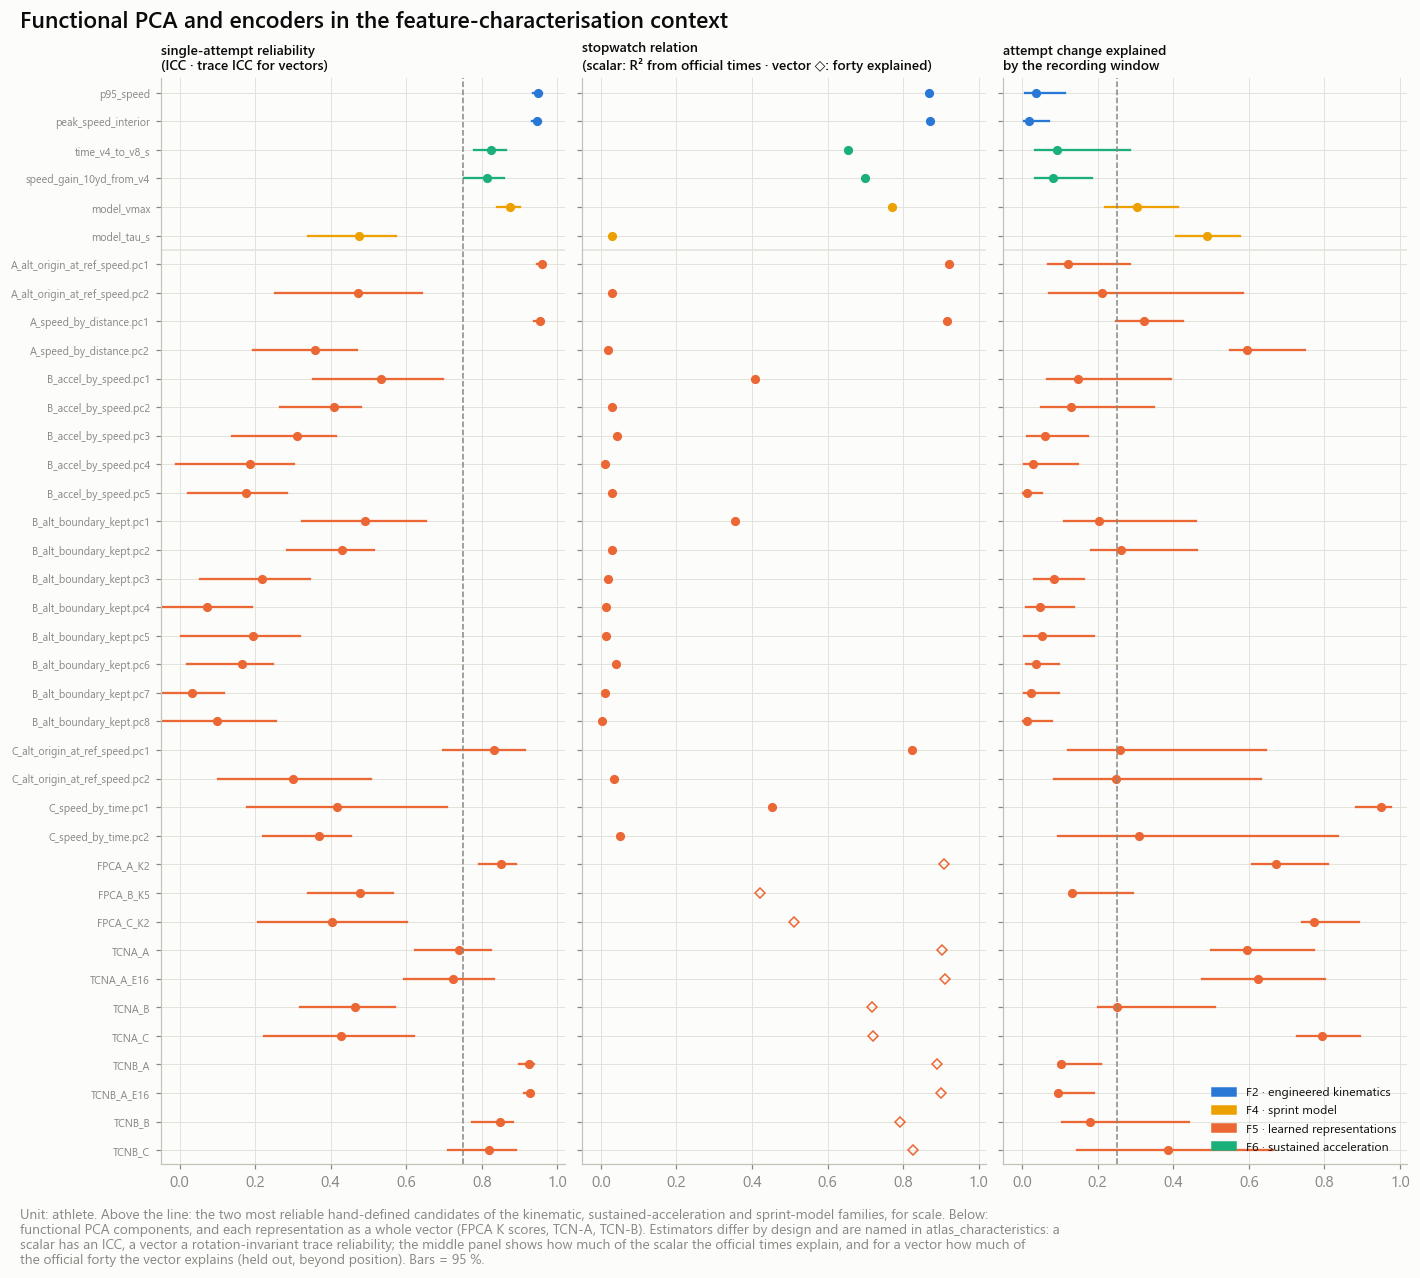

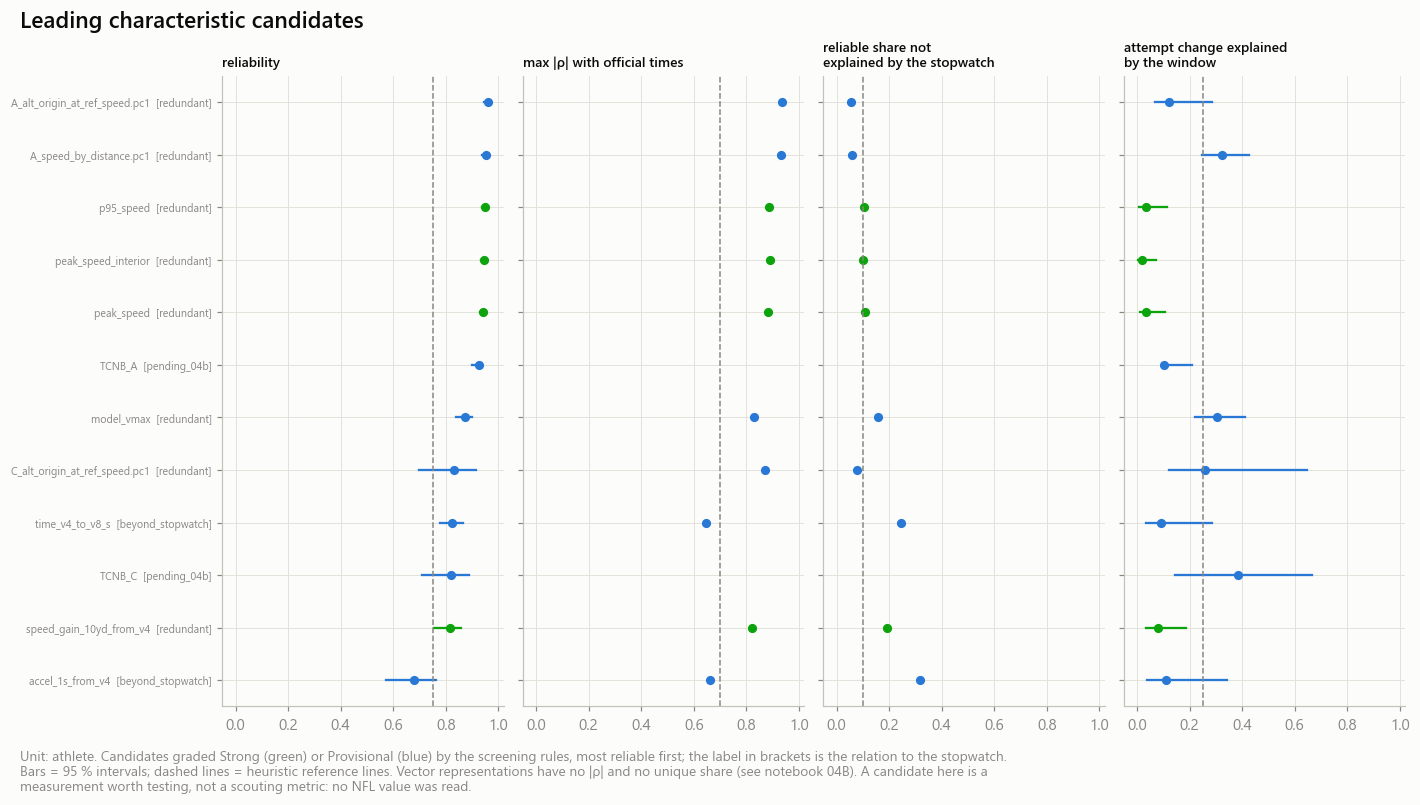

In [13]:
display(Markdown('**Screening grades by family** (unit: feature definition)'))
display(status.group_by('family', 'grade').len().pivot(on='grade', index='family', values='len').fill_null(0).sort('family'))
display(Markdown('**Candidates of the forty and learned representations** (rule-based labels, for review)'))
with pl.Config(tbl_rows=80, fmt_str_lengths=110):
    display(status.filter(FORTY_ONLY & (pl.col('role') == 'candidate'))
            .select('feature_id', 'grade', 'support', 'reliability_label', 'stopwatch_relation', 'acquisition', 'transfer_eligibility',
                    'reliability', 'redundancy_abs', 'reliable_unique_share', 'window_r2', 'reason')
            .sort('grade', 'reliability', descending=[False, True], nulls_last=True))
display(Markdown('**Official measurements** (the reference of the stopwatch comparison)'))
display(status.filter(pl.col('role') == 'reference').select('feature_id', 'grade', 'support', 'coverage_athletes', 'transfer_eligibility', 'reason'))

store.show(af.plot_learned_in_context(chars, status, c), 'AM04A_09_fpca_and_tcn_in_context', publication=True,
           source='atlas_characteristics (rows reused from notebooks 02 and 03)', n=n_rep)
store.show(af.plot_leading_candidates(chars, status, c), 'AM04A_10_leading_characteristic_candidates',
           {'status': status.filter(FORTY_ONLY & (pl.col('role') == 'candidate'))}, publication=True, source='atlas_feature_status', n=n_rep)

## 12 · Saved outputs

In [14]:
ATLAS_TABLES = [at.DICTIONARY, at.SUSTAINED, *at.CHAR_CONTRACTS, at.STATUS, at.RETENTION, at.MATRIX, at.CLUSTERS]
listing = pl.DataFrame([{'name': t.name, 'kind': t.kind, 'grain': t.area, 'key': ', '.join(t.key),
                         'parquet': cfg.paths.rel(store.parquet(t)), 'written': store.exists(t)} for t in ATLAS_TABLES])
with pl.Config(tbl_rows=30, fmt_str_lengths=110):
    display(listing)
figure_files = sorted(p.name for p in store.figures_dir.glob('AM04A_*.png'))
display(Markdown(f'**Figures** ({cfg.paths.rel(store.figures_dir)}): ' + (', '.join(figure_files) or 'none (SAVE_FIGURES is off)')))
if controls.save_tables:
    store.write_json('atlas_manifest', {
        'notebook': '04a_feature_characteristic_atlas', 'seed': controls.seed, 'atlas_version': at.ATLAS_VERSION, 'config': c.params(),
        'question': 'Which Combine measurements are well defined, repeatable within position, distinct from the stopwatch and robust '
                    'to the recording?',
        'scientific_status': 'technical check only (smoke run)' if controls.smoke else 'full-population run',
        'nfl_outcomes_read': False, 'tracked_athletes': int(a.ids.size), 'eligible_attempts': int(d.seq_ids.size),
        'definitions': dictionary.height, 'features_characterised': status.height,
        'grades': {r['grade']: r['len'] for r in status.group_by('grade').len().iter_rows(named=True)},
        'tables': [t.name for t in ATLAS_TABLES], 'figures': figure_files,
        'reused': inventory.filter(pl.col('status').str.starts_with('reused'))['artifact'].to_list(),
        'validation': {r['check']: r['status'] for r in validation_report.iter_rows(named=True)}})

name,kind,grain,key,parquet,written
str,str,str,str,str,bool
"""feature_dictionary""","""table""","""feature""","""feature_id""","""warehouse/gold/advanced_movement/atlas/feature_dictionary.parquet""",true
"""atlas_sustained""","""dataset""","""sequence × feature""","""seq_id, feature""","""warehouse/gold/advanced_movement/atlas/atlas_sustained.parquet""",true
"""atlas_coverage""","""table""","""feature × group""","""feature_id, group_type, group""","""warehouse/gold/advanced_movement/atlas/atlas_coverage.parquet""",true
"""atlas_characteristics""","""table""","""feature × scope""","""feature_id, scope""","""warehouse/gold/advanced_movement/atlas/atlas_characteristics.parquet""",true
"""atlas_reliability""","""table""","""feature × scope""","""feature_id, scope""","""warehouse/gold/advanced_movement/atlas/atlas_reliability.parquet""",true
"""atlas_nuisance_diagnostics""","""table""","""feature × variable × level""","""feature_id, variable, level""","""warehouse/gold/advanced_movement/atlas/atlas_nuisance_diagnostics.parquet""",true
"""atlas_attempt_features""","""dataset""","""feature × sequence""","""feature_id, seq_id""","""warehouse/gold/advanced_movement/atlas/atlas_attempt_features.parquet""",true
"""atlas_athlete_features""","""dataset""","""feature × athlete""","""feature_id, nfl_id""","""warehouse/gold/advanced_movement/atlas/atlas_athlete_features.parquet""",true
"""atlas_feature_status""","""table""","""feature""","""feature_id""","""warehouse/gold/advanced_movement/atlas/atlas_feature_status.parquet""",true


**Figures** (reports/figures/advanced_movement/atlas): AM04A_01_feature_inventory.png, AM04A_02_missingness_eligibility_map.png, AM04A_03_reliability_vs_stopwatch_redundancy.png, AM04A_03b_reliability_vs_redundancy_by_position.png, AM04A_04_reliability_by_family.png, AM04A_05_quality_filter_vs_retention.png, AM04A_06_recording_window_sensitivity.png, AM04A_07_feature_redundancy_matrix.png, AM04A_08_reliable_speed_vs_derivatives.png, AM04A_09_fpca_and_tcn_in_context.png, AM04A_10_leading_characteristic_candidates.png

## 13 · Conclusions

The text below is generated from the saved tables of this run. It separates seven levels of evidence — a feature exists, is measurable, is repeatable, is distinct from the stopwatch, has a plausible physical interpretation, is ready for an NFL transfer evaluation, has demonstrated NFL predictive value — and the last one is not tested in this milestone.

In [15]:
conclusions = at.conclusions_markdown(status, dictionary, c, controls.run_mode)
if controls.save_tables:
    store.tables_dir.mkdir(parents=True, exist_ok=True)
    (store.tables_dir / 'atlas_conclusions.md').write_text(conclusions, encoding='utf-8')
display(Markdown(conclusions))

_Generated from `feature_dictionary` and `atlas_feature_status` of this run (`RUN_MODE = 'full'`). Intervals are 95 %, athlete-level. Grades are heuristic screening labels for review._

**Seven levels of evidence (forty-yard dash and official measurements; candidates only from level 2)**
1. *Exists*: 1409 definitions in the dictionary (84 characterised on the forty or as official measurements; 1325 from other drills, evidence reused from Phase 04).
2. *Measurable*: 53 of 53 candidates have adequate support (coverage ≥ 0.8, ≥ 50 athletes with a repeat).
3. *Repeatable*: 12 candidates have a reliability interval above 0.75; 5 above 0.5; 19 below it.
4. *Distinct from the stopwatch*: 2 candidates carry reliable variance the official times do not explain (margin 0.1); 8 are redundant; 31 have a low correlation only, which is not evidence of new information.
5. *Plausible physical interpretation*: 20 candidates have a definition readable in physical terms; learned representations have none established.
6. *Ready for an NFL transfer evaluation*: decided by the frozen shortlist at the end of notebook 04B, not here.
7. *Demonstrated NFL predictive value*: **NOT TESTED in this milestone.** No NFL outcome was read.

**Strong candidates (4)**
- `p95_speed` (F2): reliability 0.95 [0.94, 0.96]; |ρ| with the official times 0.89; stopwatch R² 0.87; reliable share not explained 0.10; window R² 0.04; cohort R² 0.00 → redundant, acquisition robust.
- `peak_speed_interior` (F2): reliability 0.95 [0.93, 0.96]; |ρ| with the official times 0.89; stopwatch R² 0.87; reliable share not explained 0.10; window R² 0.02; cohort R² 0.00 → redundant, acquisition robust.
- `peak_speed` (F2): reliability 0.94 [0.93, 0.95]; |ρ| with the official times 0.88; stopwatch R² 0.86; reliable share not explained 0.11; window R² 0.03; cohort R² 0.00 → redundant, acquisition robust.
- `speed_gain_10yd_from_v4` (F6): reliability 0.81 [0.75, 0.86]; |ρ| with the official times 0.82; stopwatch R² 0.70; reliable share not explained 0.19; window R² 0.08; cohort R² 0.04 → redundant, acquisition robust.

**Provisional candidates (8)**
- `A_alt_origin_at_ref_speed component 1` (F5): reliability 0.96 [0.95, 0.97]; |ρ| with the official times 0.94; stopwatch R² 0.92; reliable share not explained 0.06; window R² 0.12; cohort R² 0.00 → redundant, acquisition uncertain.
- `A_speed_by_distance component 1` (F5): reliability 0.95 [0.94, 0.96]; |ρ| with the official times 0.93; stopwatch R² 0.92; reliable share not explained 0.06; window R² 0.32; cohort R² 0.00 → redundant, acquisition uncertain.
- `TCN-B · A (8-d)` (F5): reliability 0.93 [0.90, 0.94]; |ρ| with the official times n/a; stopwatch R² n/a; reliable share not explained n/a; window R² 0.10; cohort R² n/a → pending_04b, acquisition robust.
- `model_vmax` (F4): reliability 0.87 [0.84, 0.90]; |ρ| with the official times 0.83; stopwatch R² 0.77; reliable share not explained 0.16; window R² 0.30; cohort R² 0.01 → redundant, acquisition uncertain.
- `C_alt_origin_at_ref_speed component 1` (F5): reliability 0.83 [0.70, 0.92]; |ρ| with the official times 0.87; stopwatch R² 0.82; reliable share not explained 0.08; window R² 0.26; cohort R² 0.01 → redundant, acquisition uncertain.
- `time_v4_to_v8_s` (F6): reliability 0.82 [0.78, 0.86]; |ρ| with the official times 0.65; stopwatch R² 0.65; reliable share not explained 0.25; window R² 0.09; cohort R² 0.04 → beyond_stopwatch, acquisition uncertain.
- `TCN-B · C (8-d)` (F5): reliability 0.82 [0.71, 0.89]; |ρ| with the official times n/a; stopwatch R² n/a; reliable share not explained n/a; window R² 0.39; cohort R² n/a → pending_04b, acquisition uncertain.
- `accel_1s_from_v4` (F6): reliability 0.68 [0.57, 0.76]; |ρ| with the official times 0.66; stopwatch R² 0.48; reliable share not explained 0.32; window R² 0.11; cohort R² 0.09 → beyond_stopwatch, acquisition uncertain.

**Candidates by family and grade**: F2 Reject / not currently usable: 5; F2 Strong: 3; F4 Exploratory: 3; F4 Provisional: 1; F5 Exploratory: 15; F5 Provisional: 5; F5 Reject / not currently usable: 12; F6 Exploratory: 4; F6 Provisional: 2; F6 Reject / not currently usable: 2; F6 Strong: 1.

A feature with poor repeatability is not a training recommendation, and a grade is not a scouting metric: the football meaning and the usefulness of every candidate remain to be established against NFL movement.

## What this notebook does not establish

- It measures **measurements**. A repeatable feature that is distinct from the stopwatch is a candidate for a test, not a scouting metric: its football meaning and its usefulness are open until NFL movement has been examined.
- Reliability rests on two attempts per athlete. Intervals are wide in small position groups, and an ICC describes this recording set-up, not a property of the athlete in general.
- The forty recording starts after the first movement and ends near peak speed. Speed-anchored features avoid the missing start; they do not recover it.
- Linear association with the forty and the 10-yard split does not exclude a nonlinear dependence.
- The handedness of the Combine coordinate frame is unverified, so lateral channels are not used.
- Features of other drills carry Phase 04 evidence only (smoothing robustness and repeatability); their relation to official times and to the recording was not studied here.

**Next.** Notebook `04b_tcn_robustness_and_shortlist.ipynb` checks whether the TCN-B result of notebook 03 survives several training seeds, matched-stopwatch impostors and an audit of the residualisation, then freezes the shortlist of representation families for the NFL transfer study. It reads `atlas_feature_status` and `atlas_characteristics` written here.